## Import Libraries

In [55]:
# Standard libraries

import sqlite3 # SQLite database access
import warnings # Suppress non-critical warnings

# Data manipulation libraries
import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Clustering
from sklearn.preprocessing import StandardScaler # Feature scaling
from sklearn.cluster import (KMeans, DBSCAN) # clustering
from sklearn.metrics import (silhouette_score, mean_absolute_error, mean_squared_error) # Evaluation Metrics
from sklearn.model_selection import GridSearchCV# Hyperparameter tuning

# Association Rules
from mlxtend.frequent_patterns import apriori, association_rules  # Apriori algorithm

# Time Series
from statsmodels.tsa.seasonal import STL # STL decomposition
from statsmodels.tsa.stattools import adfuller # ADF stationarity test
from statsmodels.tsa.statespace.sarimax import SARIMAX # SARIMA model
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf # ACF/PACF plots

# XGBoost
from xgboost import XGBRegressor # Gradient-boosted decision tree regressor

warnings.filterwarnings('ignore')
from itertools import product

RANDOM_STATE = 42 # Fixed seed for all stochastic operations

## Database Connection

In [2]:
# Database path
DB_PATH = 'accident_data_v1.0.0_2023.db'

def get_conn():
    """Open and return a connection to the accident SQLite database."""
    return sqlite3.connect(DB_PATH)

# Connect to database
conn = sqlite3.connect(DB_PATH) # Establish a connection to the database
cur = conn.cursor() # Create a cursor object to execute SQL queries

# Get all table names from the database
tables = [t[0] for t in cur.execute(
    "SELECT name FROM sqlite_master WHERE type='table';"
).fetchall()]

# Display the list of tables found in the database
print("Tables found:", tables)

# Show row + column count
for t in tables:
    cols = cur.execute(f'PRAGMA table_info({t})').fetchall() # Get column information using PRAGMA
    rows = cur.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0] # Count total number of rows in the table
    print(f"{t}: {rows:,} rows and {len(cols)} cols")

conn.close()

Tables found: ['accident', 'casualty', 'vehicle', 'lsoa']
accident: 461,352 rows and 36 cols
casualty: 600,332 rows and 19 cols
vehicle: 849,091 rows and 28 cols
lsoa: 34,378 rows and 7 cols


## Label Mappings (STATS19 Code)
The STATS19 data uses numeric codes for categorical variables. The dictionaries below map each code to its readable label

In [3]:
# Day of week mapping
DAY_MAP   = {1:'Sunday',
             2:'Monday',
             3:'Tuesday',
             4:'Wednesday',
             5:'Thursday',
             6:'Friday',
             7:'Saturday'}

DAY_ORDER = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

# Accident severity mapping
SEVERITY_MAP = {1:'Fatal', 2:'Serious', 3:'Slight'}

# Vehicle type codes
VEHICLE_MAP = {1:'Pedal cycle', 2:'M/cycle ≤50cc', 3:'M/cycle 51-125cc',
               4:'M/cycle 126-500cc', 5:'M/cycle >500cc', 8:'Taxi/Private hire',
               9:'Car', 10:'Minibus', 11:'Bus/Coach', 16:'Ridden horse', 
               17:'Agricultural vehicle', 19:'Van ≤3.5t', 20:'HGV 3.5-7.5t',
               21:'HGV >7.5t', 90:'Other', 97:'M/cycle (cc unknown)', 99:'Unknown'}

# Light conditions
LIGHT_MAP = {1:'Daylight', 4:'Darkness: lit', 5:'Darkness: unlit',
             6:'Darkness: no lighting', 7:'Darkness: unknown'}

# Weather conditions
WEATHER_MAP = {1:'Fine/no wind', 2:'Raining/no wind', 3:'Snowing/no wind',
               4:'Fine/high wind', 5:'Raining/high wind', 6:'Snowing/high wind',
               7:'Fog/mist', 8:'Other', 9:'Unknown'}

# Road surface conditions
ROAD_SURFACE_MAP = {1:'Dry', 2:'Wet/Damp', 3:'Snow',
                    4:'Frost/Ice', 5:'Flood', 6:'Oil/Diesel', 7:'Mud'}

# Road type
ROAD_TYPE_MAP = {1:'Roundabout', 2:'One-way street', 3:'Dual carriageway',
                 6:'Single carriageway', 7:'Slip road', 9:'Unknown'}

# Speed limit (mph)
SPEED_MAP = {20:'20 mph', 30:'30 mph', 40:'40 mph',
             50:'50 mph', 60:'60 mph', 70:'70 mph'}

# Urban or rural
URBAN_MAP = {1:'Urban', 2:'Rural'}

# Police force codes
POLICE_FORCE_MAP = {1:'Metropolitan Police', 3:'Cumbria', 4:'Lancashire', 
                    5:'Merseyside', 6:'Greater Manchester', 7:'Cheshire',
                    10:'Northumbria', 11:'Durham', 12:'North Yorkshire',
                    13:'West Yorkshire', 14:'South Yorkshire', 16:'Humberside',
                    17:'Cleveland', 20:'West Midlands', 21:'Staffordshire',
                    22:'West Mercia', 23:'Warwickshire', 30:'Derbyshire',
                    31:'Nottinghamshire', 32:'Lincolnshire', 33:'Leicestershire',
                    34:'Northamptonshire', 35:'Cambridgeshire', 36:'Norfolk',
                    37:'Suffolk', 40:'Bedfordshire', 41:'Hertfordshire',42:'Essex',
                    43:'Thames Valley', 44:'Hampshire', 45:'Surrey', 46:'Kent', 
                    47:'Sussex', 48:'City of London', 50:'Devon and Cornwall',
                    52:'Avon and Somerset', 53:'Gloucestershire',54:'Wiltshire', 
                    55:'Dorset', 60:'North Wales', 61:'Gwent', 62:'South Wales',
                    63:'Dyfed-Powys', 97:'Strathclyde'}

## Load Accident Data

In [4]:
# Load accident data for selected years
def load_accidents(years):
    # Create SQL placeholders (?, ?, ...) based on number of years
    placeholders = ','.join('?' * len(years))
    
    # Open database connection and execute query
    with get_conn() as conn:
        df = pd.read_sql(
            f"SELECT * FROM accident WHERE accident_year IN ({placeholders})",
            conn,
            params=years
        )
    return df

## Handle Missing and Invalid Values

In [5]:
def impute_accidents(df):
    """
        Replace missing latitude/longitude with column median
        Replace '-1' (unknown codes) with the mode
    """
    df = df.copy()

    # Impute geographic coordinates with the column median
    for col in ['latitude', 'longitude']:
        median_val = df[col].median()  # Calculate median
        n_missing  = df[col].isna().sum() # Count missing values
       
        # Replace NaN values with median
        df[col] = df[col].fillna(median_val)
        
        # Log imputation if any values were missing
        if n_missing:
            print(f'Imputed {n_missing} missing {col} values')
            
    # Replace -1 (STATS19 unknown flag) with column mode for categorical columns
    coded_cols = ['weather_conditions', 'road_surface_conditions', 
                  'light_conditions', 'road_type', 'speed_limit', 
                  'urban_or_rural_area', 'junction_detail', 'junction_control',
                  'pedestrian_crossing_human_control', 'pedestrian_crossing_physical_facilities',
                  'special_conditions_at_site', 'carriageway_hazards',
                  'did_police_officer_attend_scene_of_accident']
    
    for col in coded_cols:
        if col in df.columns:
             # Count how many invalid (-1) values exist
            n_flag = (df[col] == -1).sum()
            
            if n_flag:
                # Replace -1 with most common valid value
                mode_val = df.loc[df[col] != -1, col].mode()[0]
                df[col]  = df[col].replace(-1, mode_val)

    return df

## Data Cleaning and Feature Engineering 

In [6]:
# Convert dates and add readable labels
def clean_accidents(df):
    """
    Dataset is prepared for analysis by:
    - Converting date/time fields
    - Creating new features (hour)
    - Mapping coded values to readable labels
    """
    df = df.copy()

    # Convert date and extract hour
    df['date'] = pd.to_datetime(df['date'], dayfirst=True, errors='coerce')
    df['hour'] = pd.to_datetime(df['time'], format='%H:%M', errors='coerce').dt.hour

    # Map numeric codes to readable labels
    df['day_name'] = df['day_of_week'].map(DAY_MAP)
    df['severity_label'] = df['accident_severity'].map(SEVERITY_MAP)
    df['light_label'] = df['light_conditions'].map(LIGHT_MAP)
    df['weather_label'] = df['weather_conditions'].map(WEATHER_MAP)
    df['surface_label'] = df['road_surface_conditions'].map(ROAD_SURFACE_MAP)
    df['road_type_label'] = df['road_type'].map(ROAD_TYPE_MAP)
    df['speed_label'] = df['speed_limit'].map(SPEED_MAP)
    df['urban_label'] = df['urban_or_rural_area'].map(URBAN_MAP)
    df['force_name'] = df['police_force'].map(POLICE_FORCE_MAP)

    # Ensure days are ordered correctly (important for visualization)
    df['day_name'] = pd.Categorical(df['day_name'],
                                    categories=DAY_ORDER,
                                    ordered=True)

    return df

## Time Period Feature

In [7]:
# Convert hour into time-of-day category
def time_period_label(hour):
    if hour < 6:
        return 'Night'
    elif hour < 12:
        return 'Morning'
    elif hour < 18:
        return 'Afternoon'
    else:
        return 'Evening'

## Load Accident Data

In [8]:
acc2018_raw = load_accidents([2018])
acc2018_raw = impute_accidents(acc2018_raw)
acc2018 = clean_accidents(acc2018_raw)

Imputed 55 missing latitude values
Imputed 55 missing longitude values


## Load Other Tables

In [9]:
# Load vehicle, casualty, and LSOA data
with get_conn() as conn:
    veh2018 = pd.read_sql("SELECT * FROM vehicle WHERE accident_year = 2018", conn)
    cas2018 = pd.read_sql("SELECT * FROM casualty WHERE accident_year = 2018", conn)
    lsoa_df = pd.read_sql("SELECT lsoa01cd, lsoa01nm FROM lsoa", conn)

# Add readable vehicle labels
veh2018['vehicle_label'] = veh2018['vehicle_type'].map(VEHICLE_MAP)

## Data Check

In [10]:
# Quick data quality check
print(f"Accidents: {len(acc2018):,}")
print(f"Vehicles: {len(veh2018):,}")
print(f"Casualties: {len(cas2018):,}")
print(f"LSOA: {len(lsoa_df):,}")

print(f"Missing hour: {acc2018['hour'].isna().sum():,}")
print(f"Missing date: {acc2018['date'].isna().sum():,}")
print(f"Missing lat/lon: {acc2018[['latitude','longitude']].isna().any(axis=1).sum():,}")

Accidents: 122,635
Vehicles: 226,409
Casualties: 160,597
LSOA: 34,378
Missing hour: 0
Missing date: 0
Missing lat/lon: 0


##
## Task 1: Are certain hours and days significantly more accident-prone?
**Hourly and Daily Accident Counts**

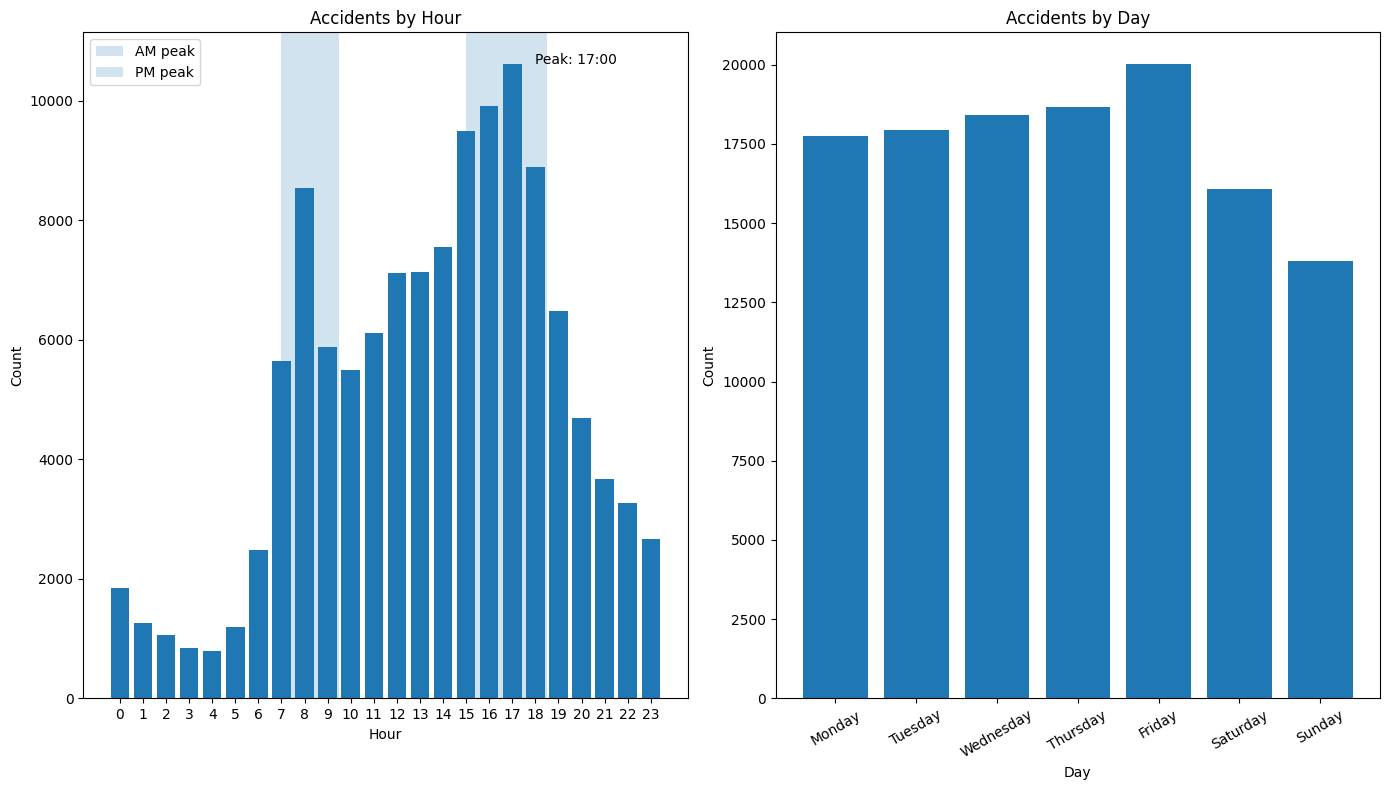

Peak hour: 17:00 (10,615)
Peak day : Friday (20,021)
Quietest : 4:00 (798)


In [16]:
# Remove rows with missing hour values
t1 = acc2018.dropna(subset=['hour'])

# Group data to count number of accidents:
# hourly: counts for each hour (0–23)
# daily: counts for each day of the week
hourly = t1.groupby('hour').size().reindex(range(24), fill_value=0)
daily  = t1.groupby('day_name', observed=True).size().reindex(DAY_ORDER, fill_value=0)

# Create a figure with two side-by-side plots
fig, ax = plt.subplots(1, 2, figsize=(14, 8))

# Hourly accidents (Bar chart showing number of accidents per hour)
ax[0].bar(hourly.index, hourly.values)

# Highlight peak commuting periods (morning and evening)
ax[0].axvspan(7, 9.5, alpha=0.2, label='AM peak')
ax[0].axvspan(15, 18.5, alpha=0.2, label='PM peak')

# Identify and annotate the hour with the highest number of accidents
peak_h = hourly.idxmax()
ax[0].annotate(f'Peak: {peak_h}:00',
               (peak_h, hourly[peak_h]),
               xytext=(peak_h + 1, hourly[peak_h]))

# Set axis labels, title, and ticks
ax[0].set(title='Accidents by Hour', xlabel='Hour', ylabel='Count')
ax[0].set_xticks(range(24))
ax[0].legend()

# Daily accidents (Bar chart showing number of accidents per day of the week)
ax[1].bar(DAY_ORDER, daily.values)

# Set axis labels and rotate x-axis labels for readability
ax[1].set(title='Accidents by Day', xlabel='Day', ylabel='Count')
ax[1].tick_params(axis='x', rotation=30)

# Display plot
plt.tight_layout()
plt.show()

# Summary output (for key insights)
print(f'Peak hour: {peak_h}:00 ({hourly.max():,})')
print(f'Peak day : {daily.idxmax()} ({daily.max():,})')
print(f'Quietest : {hourly.idxmin()}:00 ({hourly.min():,})')

###
**Heatmap of Accidents by Hour and Day**

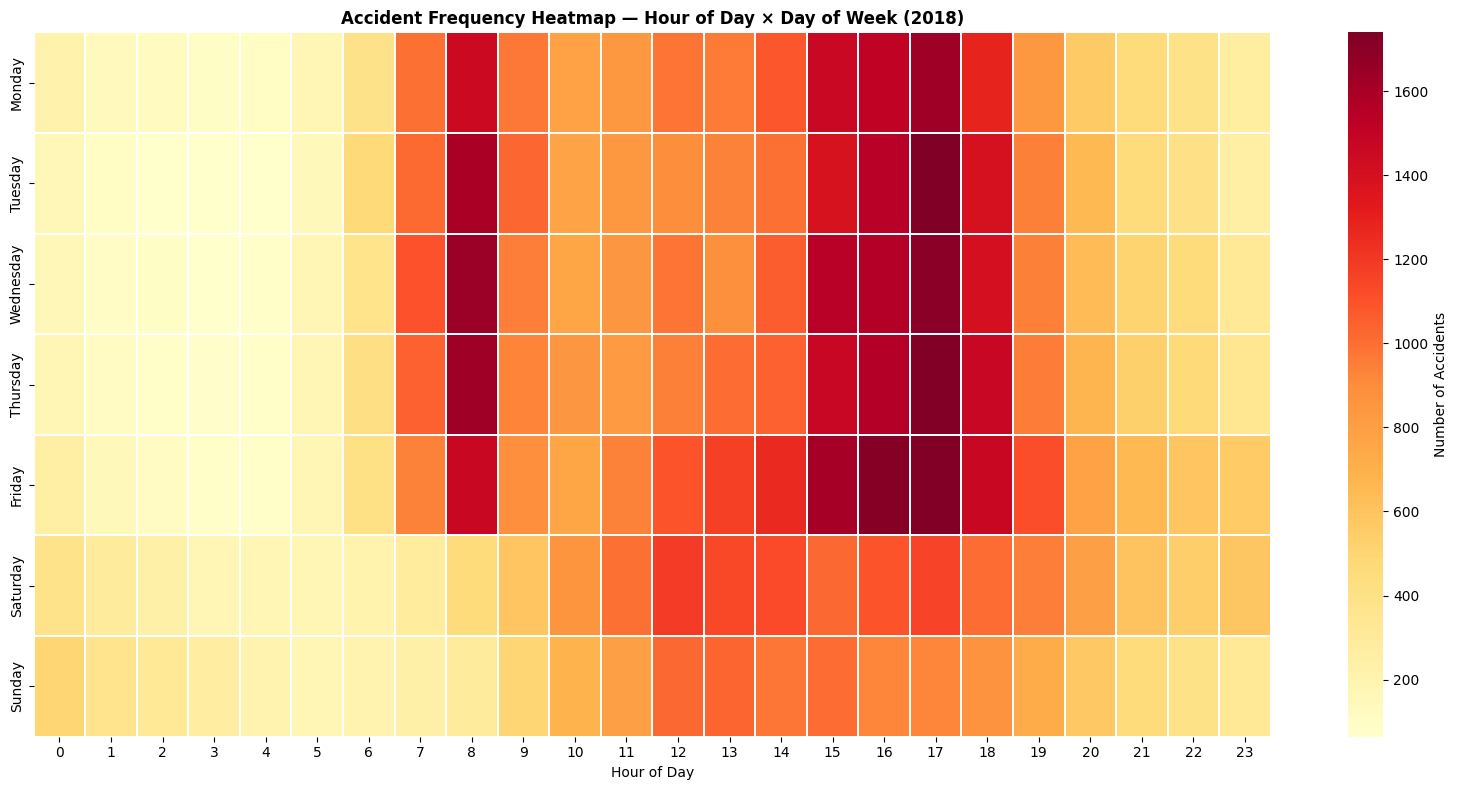

In [17]:
# Pivot table: rows = days of week, columns = hours
pivot_t1 = (
    t1.groupby(['day_name', 'hour'], observed=True)
      .size()
      .unstack(fill_value=0) # Convert to matrix form (hours as columns)
      .reindex(DAY_ORDER) # Ensure correct day order (Mon-Sun)
)

# Create heatmap figure
plt.figure(figsize=(16, 8))

# Plot heatmap:
# - Darker colours indicate higher accident frequency
# - Colour bar shows the scale of accident counts
sns.heatmap(pivot_t1, cmap='YlOrRd', linewidths=0.2,
            cbar_kws={'label': 'Number of Accidents'})

# Add title and axis labels
plt.title('Accident Frequency Heatmap — Hour of Day × Day of Week (2018)',
          fontsize=12, fontweight='bold')
plt.xlabel('Hour of Day')
plt.ylabel('')

# Display plot
plt.tight_layout()
plt.show()

###
**Severity Breakdown by Hour**

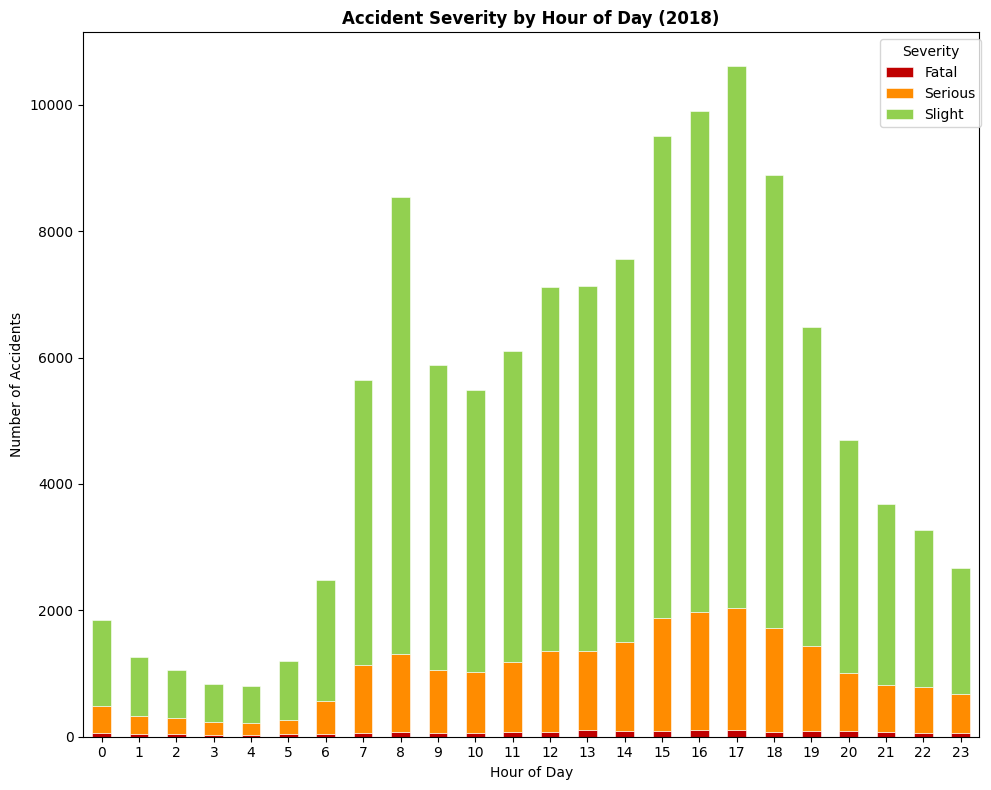

Hours with highest fatal proportion (%):
hour
3    4.19
2    3.99
4    3.88
5    3.42
0    3.41
Name: fatal_percent, dtype: float64


In [18]:
# Aggregate accident counts by hour and severity level
# - Rows = hours (0–23)
# - Columns = severity categories (Fatal, Serious, Slight)
sev_hour = (
    t1.groupby(['hour', 'severity_label'])
      .size()
      .unstack(fill_value=0)
      [['Fatal', 'Serious', 'Slight']]   # Ensure consistent column order
)

# Plot stacked bar chart:
# - Each bar represents total accidents per hour
# - Colours show severity composition within each hour
sev_hour.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 8),
    color=['#C00000', '#FF8C00', '#92D050'],  # Red = Fatal, Orange = Serious, Green = Slight
    edgecolor='white',
    linewidth=0.4
)

# Add titles and labels
plt.title(
    'Accident Severity by Hour of Day (2018)',
    fontsize=12,
    fontweight='bold'
)
plt.xlabel('Hour of Day')
plt.ylabel('Number of Accidents')

# Improve readability of x-axis labels
plt.xticks(rotation=0)

# Place legend outside plot for clarity
plt.legend(title='Severity', bbox_to_anchor=(1.01, 1))

# Adjust layout and display plot
plt.tight_layout()
plt.show()

# Calculate percentage of fatal accidents per hour
sev_hour['fatal_percent'] = (sev_hour['Fatal'] / sev_hour.sum(axis=1) * 100).round(2)

# Display top 5 hours with highest fatality proportion
print('Hours with highest fatal proportion (%):')
print(sev_hour['fatal_percent'].nlargest(5))

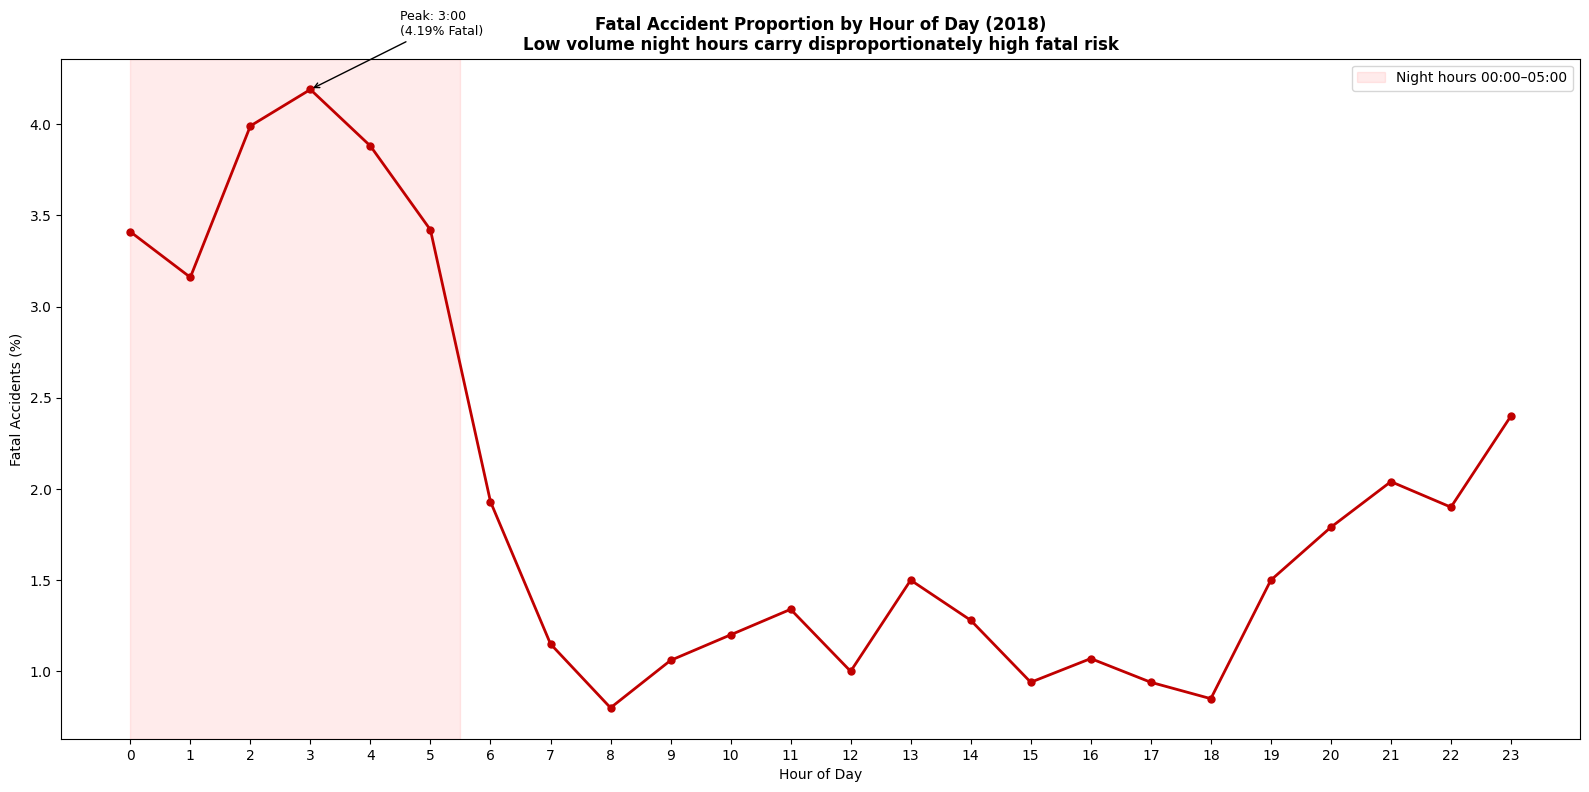

In [19]:
# Visualise fatal accident proportion by hour

plt.figure(figsize=(16, 8))

# Line plot of fatal accident percentage by hour
plt.plot(sev_hour.index, sev_hour['fatal_percent'],
         color='#C00000', linewidth=2, marker='o', markersize=5)


# Highlight night hours (00:00–05:00)
plt.axvspan(0, 5.5, alpha=0.08, color='red',
            label='Night hours 00:00–05:00')


# Annotate peak fatal risk hour
peak_h = sev_hour['fatal_percent'].idxmax()
peak_v = sev_hour['fatal_percent'].max()

plt.annotate(
    f'Peak: {peak_h}:00\n({peak_v:.2f}% Fatal)',
    xy=(peak_h, peak_v),
    xytext=(peak_h + 1.5, peak_v + 0.3),
    fontsize=9,
    arrowprops=dict(arrowstyle='->', color='black')
)


# Axis labels and title
plt.xlabel('Hour of Day')
plt.ylabel('Fatal Accidents (%)')
plt.title(
    'Fatal Accident Proportion by Hour of Day (2018)\n'
    'Low volume night hours carry disproportionately high fatal risk',
    fontsize=12, fontweight='bold'
)

plt.xticks(range(0, 24))
plt.legend()


# Adjust layout and display
plt.tight_layout()
plt.show()

##
## Task 2: Motorcycle Accident Patterns by Hour and Day
Motorcycle vehicles are filtered from the vehicle table and grouped into three engine categories: ≤125cc, 126–500cc, and >500cc. Hourly and daily distributions are compared across categories.

**Filter and Categorise Motorcycle Vehicles**

In [20]:
# Define STATS19 motorcycle vehicle type codes:
# 2 = ≤50cc, 3 = 51–125cc, 4 = 126–500cc, 5 = >500cc
MOTO_CODES = [2, 3, 4, 5]

def assign_moto_category(code):
    # Convert raw STATS19 vehicle_type codes into broader engine size categories.
    if code in [2, 3]:
        return '≤125cc'
    elif code == 4:
        return '126–500cc'
    elif code == 5:
        return '>500cc'
    return 'Other'  # Fallback

# Filter motorcycle records (Keep only rows where vehicle_type matches motorcycle codes)
moto_veh = veh2018[veh2018['vehicle_type'].isin(MOTO_CODES)].copy()

# Create a new column with grouped motorcycle categories
moto_veh['moto_cat'] = moto_veh['vehicle_type'].apply(assign_moto_category)

# Merge with accident-level data
# Attach time (hour), day, and severity information to each motorcycle record
moto = moto_veh.merge(
    acc2018[['accident_index', 'hour', 'day_name', 'severity_label']],
    on='accident_index',
    how='left'
)

# Remove records with missing key fields (hour or day)
moto = moto.dropna(subset=['hour', 'day_name'])

# Summary statistics
# Display number of records in each motorcycle category
print('Motorcycle records by category:')
print(moto['moto_cat'].value_counts())

# Display total number of motorcycle records
print(f'Total motorcycle records: {len(moto):,}')

Motorcycle records by category:
moto_cat
≤125cc       9362
>500cc       5876
126–500cc    2240
Name: count, dtype: int64
Total motorcycle records: 17,478


###
**Hourly Distributions by Motorcycle Category**

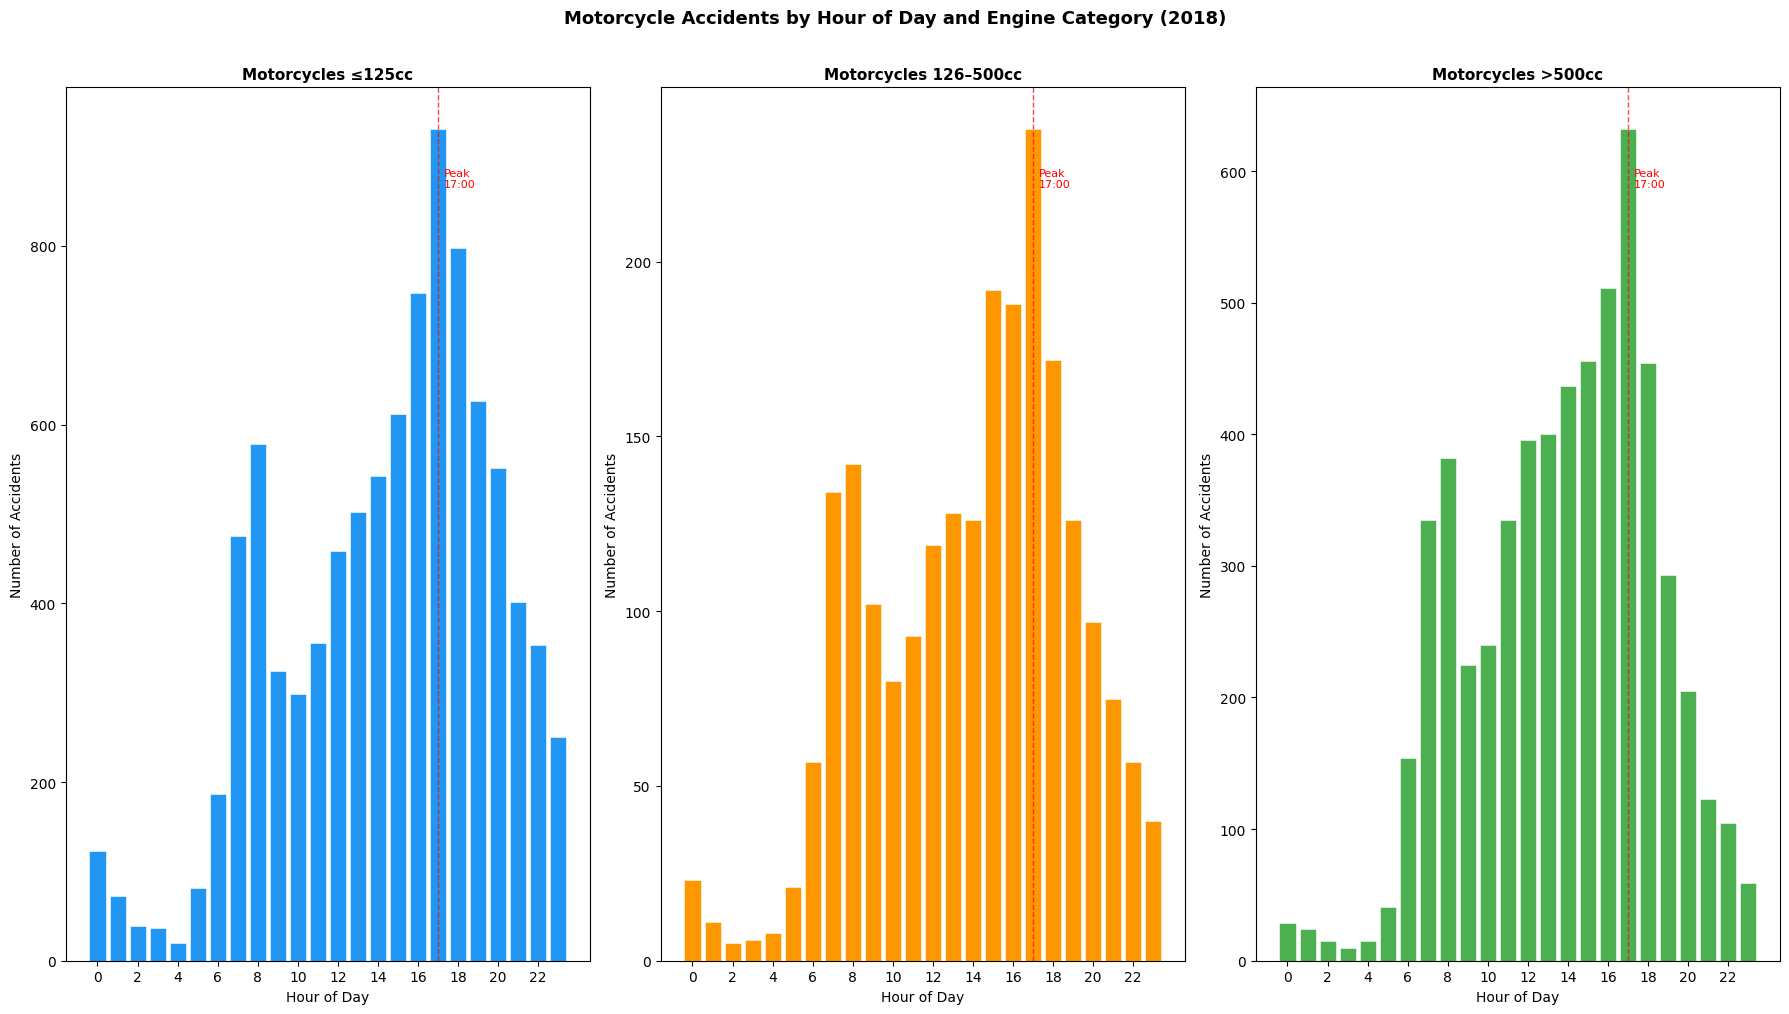

In [21]:
# Define the motorcycle categories and their plot colours
MOTO_CATS   = ['≤125cc', '126–500cc', '>500cc']
MOTO_COLORS = ['#2196F3', '#FF9800', '#4CAF50']  # Blue, Orange, Green

# Create a 1x3 subplot layout (one chart per category)
fig, axes = plt.subplots(1, 3, figsize=(18, 10))

# Loop through each category and corresponding axis/colour
for ax, cat, col in zip(axes, MOTO_CATS, MOTO_COLORS):

    # Filter dataset for the current motorcycle category
    sub = moto[moto['moto_cat'] == cat]

    # Count accidents per hour (0–23), ensuring all hours appear
    h_counts = sub.groupby('hour').size().reindex(range(24), fill_value=0)

    # Plot hourly accident counts as a bar chart
    ax.bar(h_counts.index, h_counts.values,
           color=col, edgecolor='white', linewidth=0.4)

    # Identify the peak hour (highest number of accidents)
    pk = int(h_counts.idxmax())

    # Draw a vertical dashed line at the peak hour
    ax.axvline(pk, color='red', linestyle='--', linewidth=1, alpha=0.7)

    # Add a label near the peak to highlight it
    ax.text(pk + 0.3, h_counts.max() * 0.93,
            f'Peak\n{pk}:00', color='red', fontsize=8)

    # Set axis labels and title for each subplot
    ax.set_title(f'Motorcycles {cat}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Hour of Day')
    ax.set_ylabel('Number of Accidents')

    # Show x-axis ticks every 2 hours for readability
    ax.set_xticks(range(0, 24, 2))

# Add an overall title for the full figure
plt.suptitle('Motorcycle Accidents by Hour of Day and Engine Category (2018)',
             fontsize=13, fontweight='bold', y=1.01)

# Adjust layout to prevent overlapping elements
plt.tight_layout()

# Display the plot
plt.show()

###
**Daily Distributions and Heatmaps by Motorcycle Category**

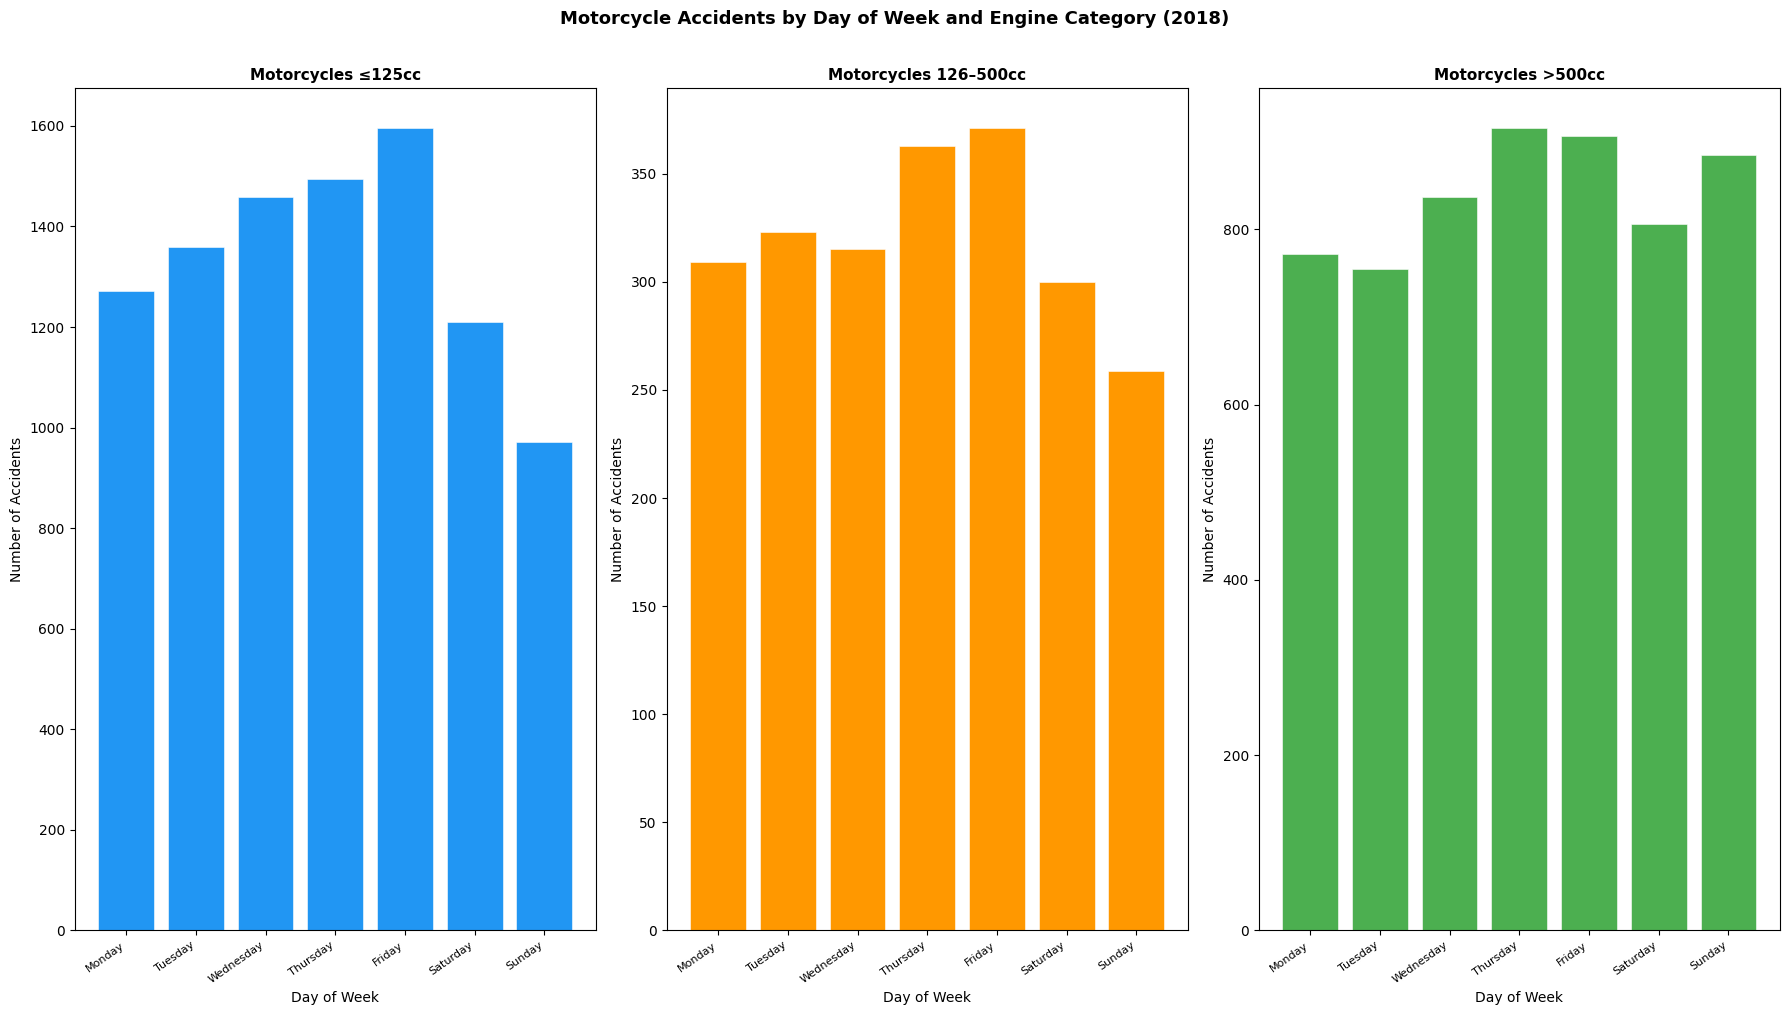

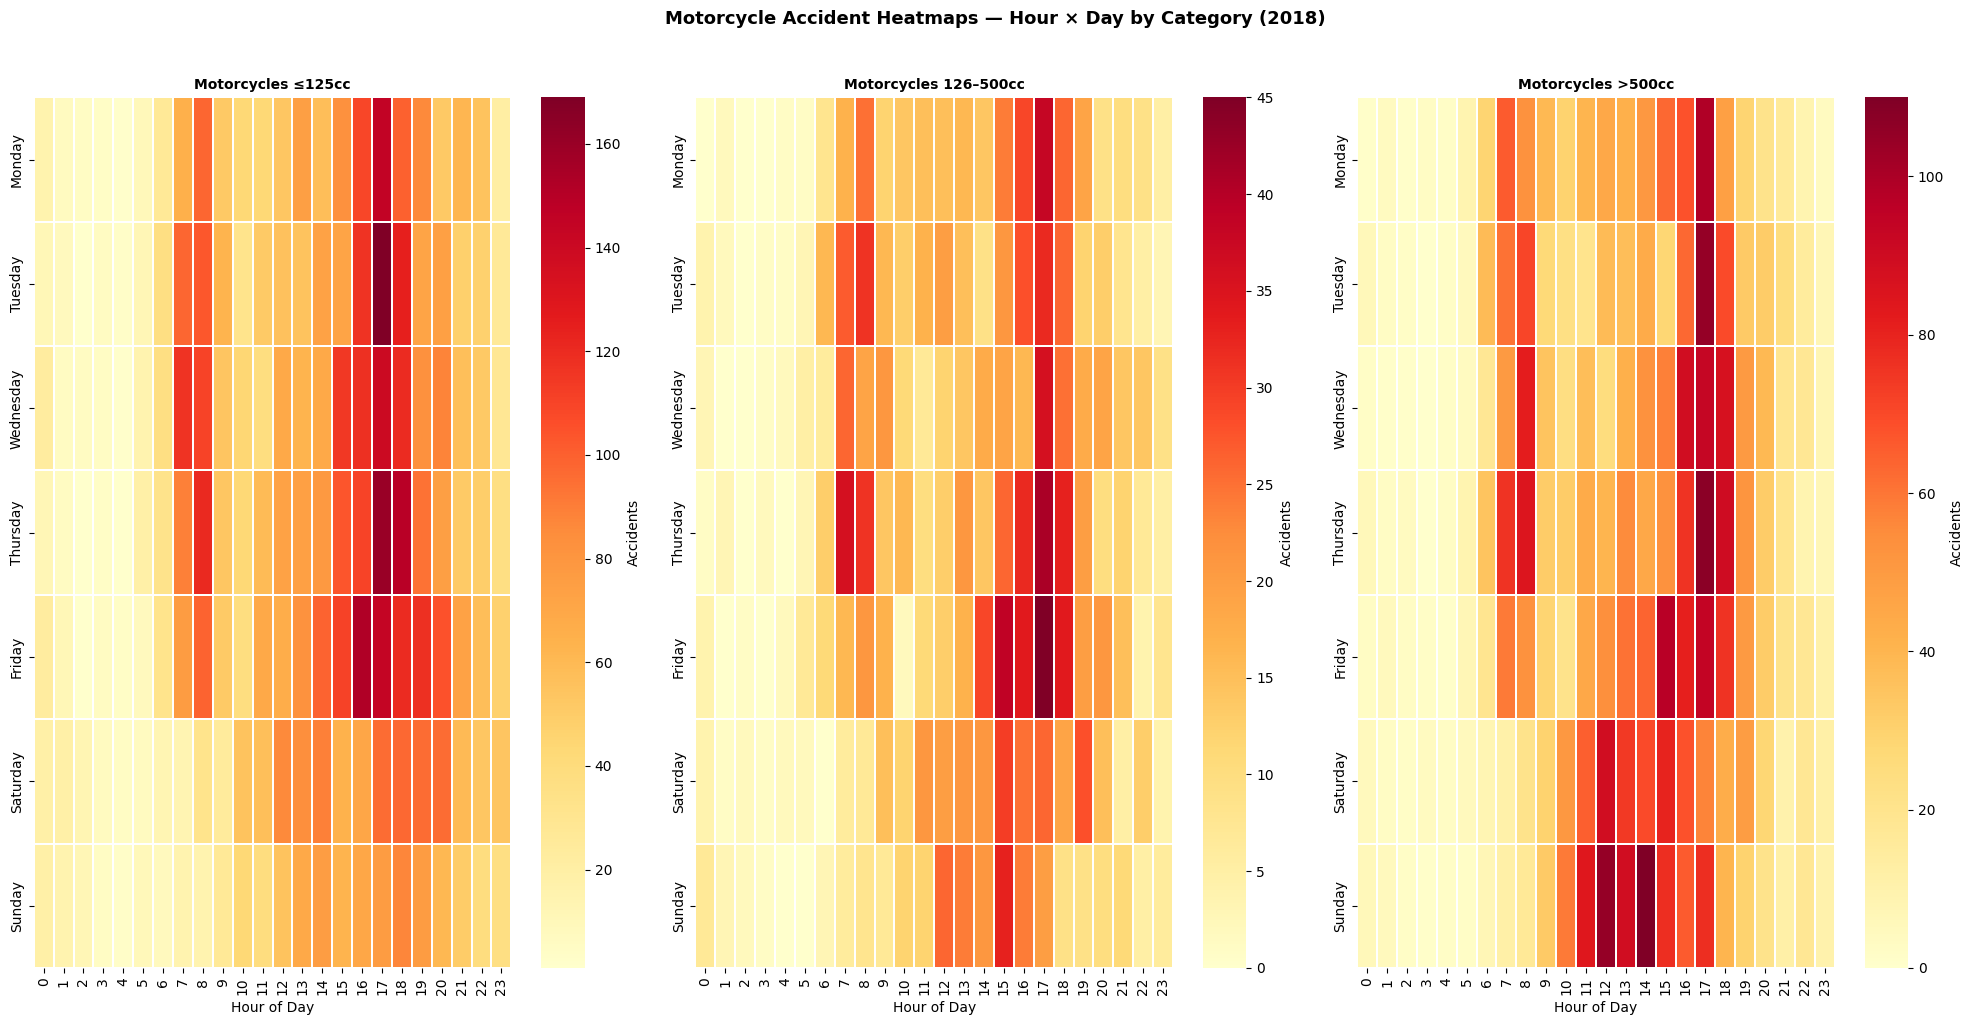

In [22]:
# Daily accident counts (bar charts)
# Create a 1x3 layout (one plot per motorcycle category)
fig, axes = plt.subplots(1, 3, figsize=(18, 10))

# Loop through each category, axis, and colour
for ax, cat, col in zip(axes, MOTO_CATS, MOTO_COLORS):

    # Filter data for the current motorcycle category
    sub = moto[moto['moto_cat'] == cat].copy()

    # Convert categorical day_name to string for grouping
    sub['day_str'] = sub['day_name'].astype(str)

    # Count accidents per day and ensure all days are included
    d_counts = (sub.groupby('day_str').size().reindex(DAY_ORDER, fill_value=0))

    # Plot daily accident counts as a bar chart
    ax.bar(range(7), d_counts.values,
           color=col, edgecolor='white', linewidth=0.4)

    # Format x-axis with day labels
    ax.set_xticks(range(7))
    ax.set_xticklabels(DAY_ORDER, rotation=35, ha='right', fontsize=8)

    # Add titles and axis labels
    ax.set_title(f'Motorcycles {cat}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Day of Week')
    ax.set_ylabel('Number of Accidents')

# Add overall title for the figure
plt.suptitle('Motorcycle Accidents by Day of Week and Engine Category (2018)',
             fontsize=13, fontweight='bold', y=1.01)

# Adjust layout
plt.tight_layout()

# Display plot
plt.show()



# Heatmaps: Hour × Day per category
# Create a 1x3 layout for heatmaps
fig, axes = plt.subplots(1, 3, figsize=(20, 10))

# Loop through each motorcycle category
for ax, cat in zip(axes, MOTO_CATS):

    # Filter data for the current category
    sub = moto[moto['moto_cat'] == cat].copy()

    # Convert day_name to string for grouping
    sub['day_str'] = sub['day_name'].astype(str)

    # Create pivot table: rows = day, columns = hour
    piv = (
        sub.groupby(['day_str', 'hour'])
           .size()
           .unstack(fill_value=0)
           .reindex(DAY_ORDER)
    )

    # Plot heatmap of accident frequency
    sns.heatmap(
        piv,
        cmap='YlOrRd',
        ax=ax,
        linewidths=0.2,
        cbar_kws={'label': 'Accidents'}
    )

    # Add titles and labels
    ax.set_title(f'Motorcycles {cat}', fontsize=10, fontweight='bold')
    ax.set_xlabel('Hour of Day')
    ax.set_ylabel('')

# Add overall title for heatmaps
plt.suptitle('Motorcycle Accident Heatmaps — Hour × Day by Category (2018)',
             fontsize=13, fontweight='bold', y=1.02)

# Adjust layout
plt.tight_layout()

# Display heatmaps
plt.show()

##
## Task 3: Pedestrian Accident Patterns by Hour and Day

**Filter Pedestrian Accidents**

In [23]:
# Filter casualty records to include only pedestrians(STATS19 coding: 3 = Pedestrian)
ped_cas = cas2018[cas2018['casualty_class'] == 3]

# Extract unique accident IDs where at least one pedestrian was involved
ped_idx = ped_cas['accident_index'].unique()

# Filter the main accident dataset to include only pedestrian-related accidents
ped_acc = acc2018[acc2018['accident_index'].isin(ped_idx)].copy()


# Summary statistics
# Total number of pedestrian casualties
print(f'Pedestrian casualties (2018): {len(ped_cas):,}')

# Total number of accidents involving pedestrians
print(f'Accidents involving pedestrians (2018): {len(ped_acc):,}')

# Percentage of all accidents that involved pedestrians
print(f'As a percentage of all 2018 accidents: {len(ped_acc)/len(acc2018)*100:.1f}%')

Pedestrian casualties (2018): 22,432
Accidents involving pedestrians (2018): 21,644
As a percentage of all 2018 accidents: 17.6%


###
**Hourly and Daily Pedestrian Accident Plots**

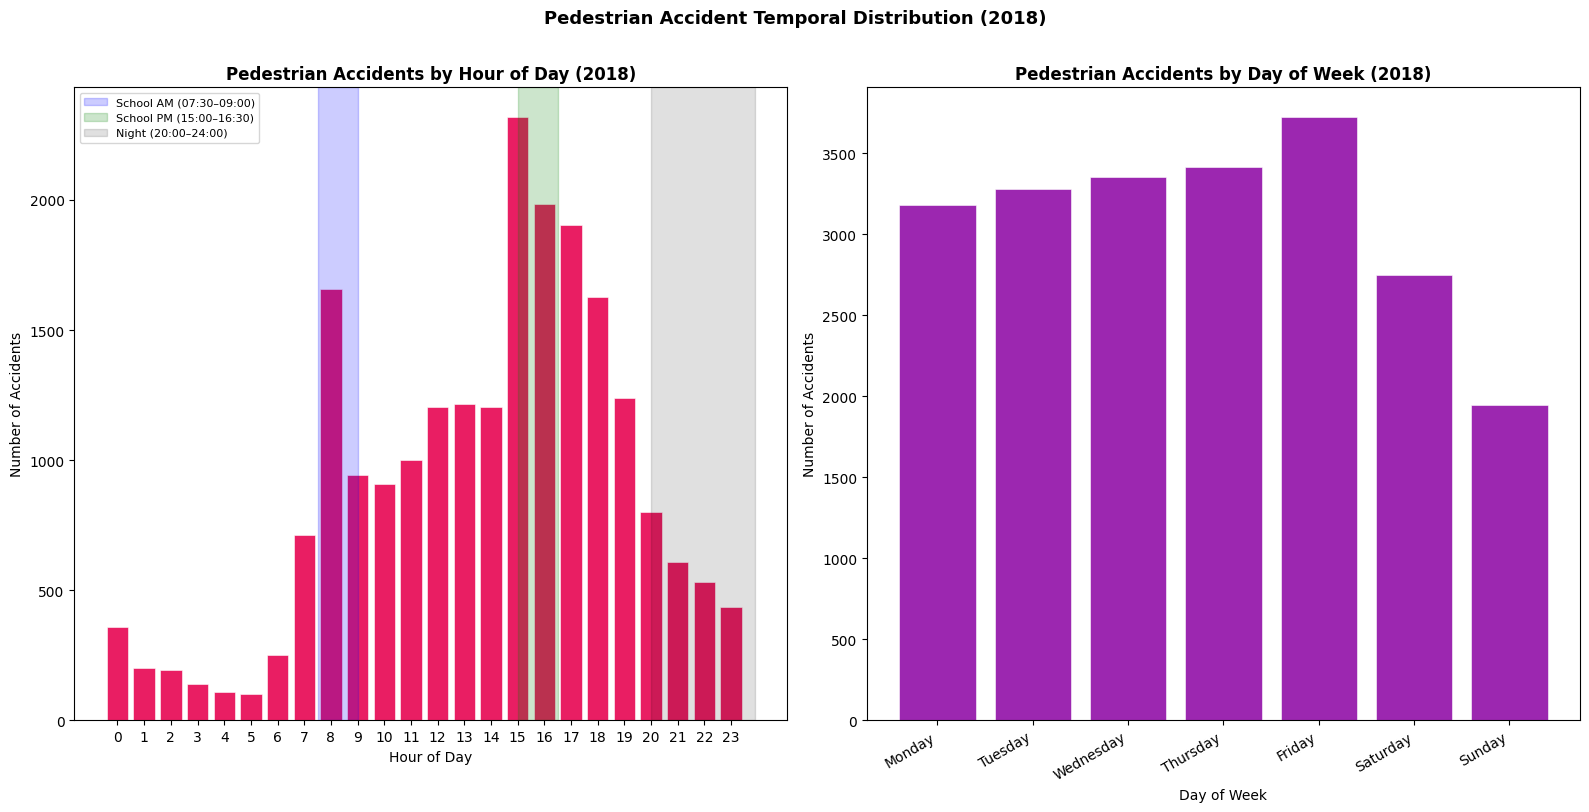

In [24]:
# Remove records where hour is missing (invalid or unparsed time)
ped_h = ped_acc.dropna(subset=['hour'])

# Count pedestrian accidents per hour (0–23), ensuring all hours are included
ped_hourly = ped_h.groupby('hour').size().reindex(range(24), fill_value=0)

# Count pedestrian accidents per day of the week
ped_daily = (ped_acc.groupby('day_name', observed=True).size().reindex(DAY_ORDER, fill_value=0))

# Create a 1x2 layout for hourly and daily plots
fig, axes = plt.subplots(1, 2, figsize=(16, 8))


# Hourly plot
# Plot number of pedestrian accidents by hour
axes[0].bar(ped_hourly.index, ped_hourly.values,
            color='#E91E63', edgecolor='white', linewidth=0.4)

# Highlight key time periods (school runs and night-time risk)
axes[0].axvspan(7.5, 9.0, alpha=0.2, color='blue',
                label='School AM (07:30–09:00)')
axes[0].axvspan(15.0, 16.5, alpha=0.2, color='green',
                label='School PM (15:00–16:30)')
axes[0].axvspan(20.0, 23.9, alpha=0.12, color='black',
                label='Night (20:00–24:00)')

# Add labels and formatting
axes[0].set_title('Pedestrian Accidents by Hour of Day (2018)',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Number of Accidents')
axes[0].set_xticks(range(0, 24))
axes[0].legend(fontsize=8)


# Daily plot
# Plot number of pedestrian accidents by day of the week
axes[1].bar(range(7), ped_daily.values,
            color='#9C27B0', edgecolor='white', linewidth=0.4)

# Format x-axis with day labels
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(DAY_ORDER, rotation=30, ha='right')

# Add labels and formatting
axes[1].set_title('Pedestrian Accidents by Day of Week (2018)',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Number of Accidents')


# Final layout and output
plt.suptitle('Pedestrian Accident Temporal Distribution (2018)',
             fontsize=13, fontweight='bold', y=1.01)

# Adjust layout to prevent overlap
plt.tight_layout()

# Display the plots
plt.show()

###
**Pedestrian Heatmap and Light Conditions**

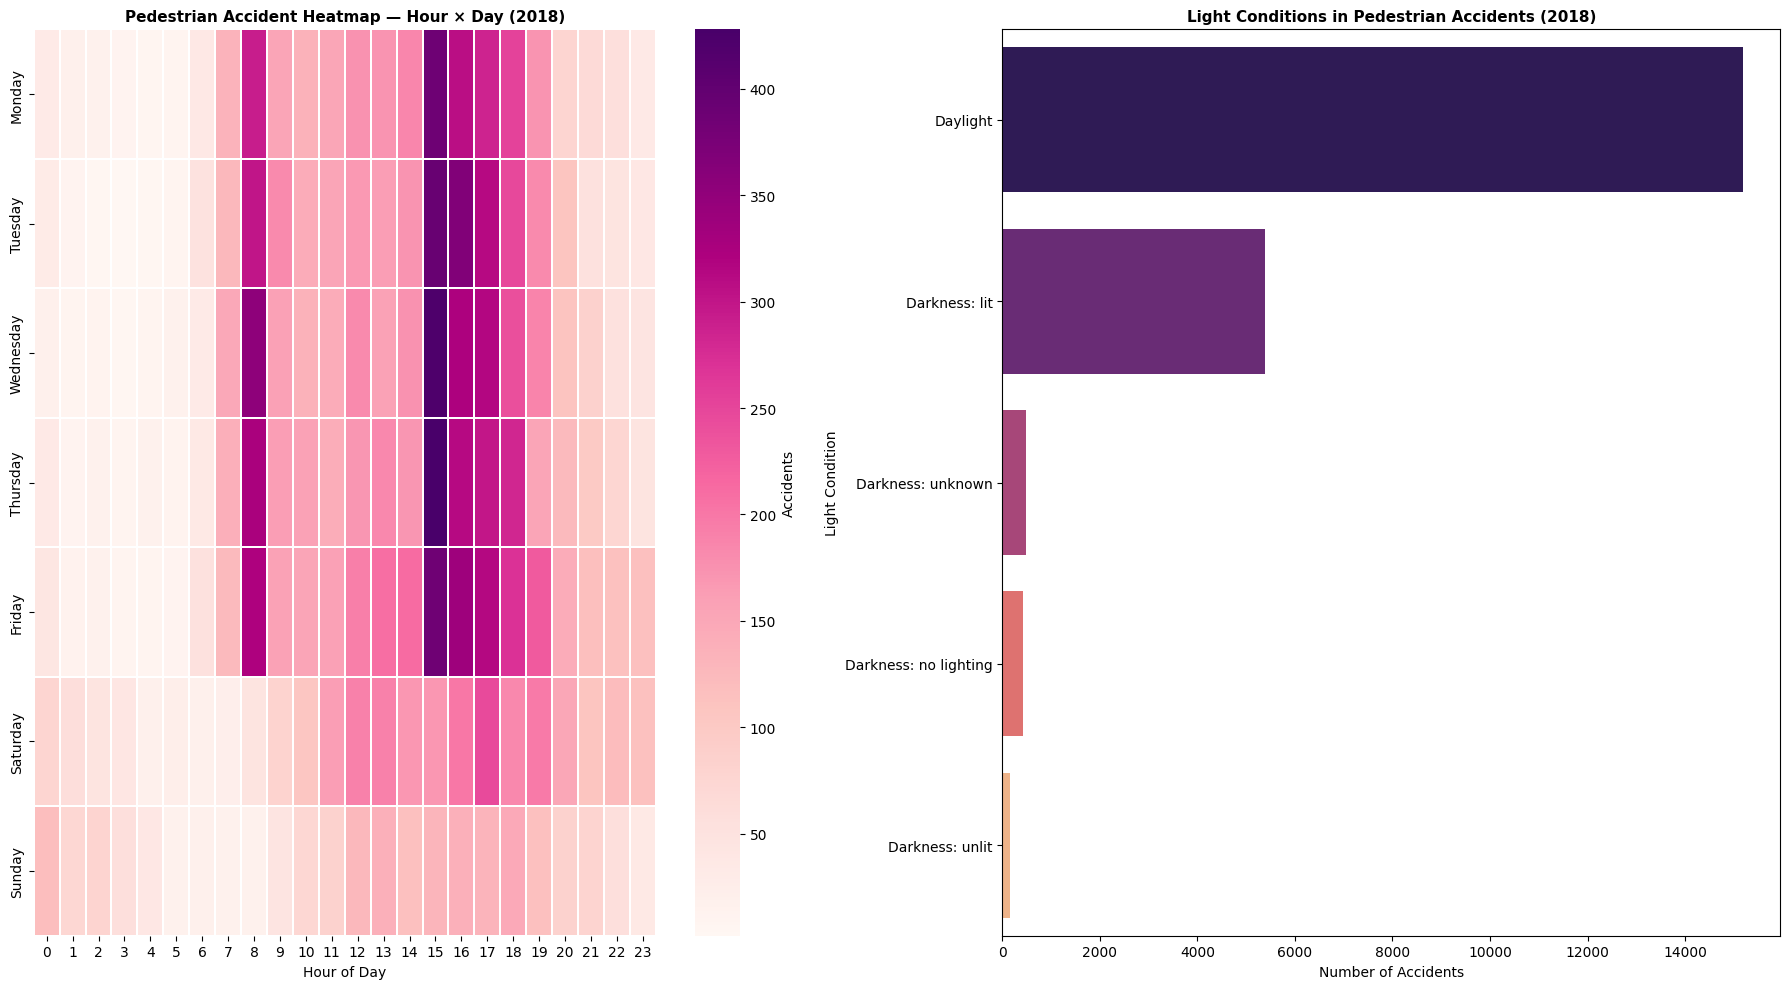

Pedestrian accidents in darkness: 6,456 (29.8%)


In [25]:
# Create a pivot table:
# Rows = day of week, Columns = hour of day, Values = accident counts
ped_piv = (
    ped_h.groupby(['day_name', 'hour'], observed=True)
         .size()
         .unstack(fill_value=0)
         .reindex(DAY_ORDER)
)

# Create a 1x2 layout (heatmap + bar chart)
fig, axes = plt.subplots(1, 2, figsize=(18, 10))


# Heatmap (Visualises when pedestrian accidents are most frequent)
sns.heatmap(ped_piv,
            cmap='RdPu',
            ax=axes[0],
            linewidths=0.2,
            cbar_kws={'label': 'Accidents'})

# Add titles and labels
axes[0].set_title('Pedestrian Accident Heatmap — Hour × Day (2018)',
                  fontsize=11, fontweight='bold')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('')


# Count accidents by lighting condition (e.g. daylight vs darkness)
light_counts = (ped_acc['light_label'].value_counts().dropna().reset_index())

# Rename columns for clarity in plotting
light_counts.columns = ['Light Condition', 'Count']

# Plot horizontal bar chart of light conditions
sns.barplot(data=light_counts, 
            x='Count',
            y='Light Condition',
            palette='magma',
            ax=axes[1])

# Add titles and labels
axes[1].set_title('Light Conditions in Pedestrian Accidents (2018)',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('Number of Accidents')


# Adjust layout
plt.tight_layout()

# Display plots
plt.show()


# Summary: Darkness proportion
# Count how many pedestrian accidents occurred in darkness
dark = ped_acc['light_label'].str.startswith('Darkness', na=False).sum()

# Print total and percentage
print(f'Pedestrian accidents in darkness: {dark:,} ({dark/len(ped_acc)*100:.1f}%)')

##
## Task 4: Apriori Algorithm (Impact of Selected Variables on Accident Severity)

Three hypothesis rules are manually evaluated (Support, Confidence, Lift, Conviction, PS) before running the Apriori algorithm. One-hot encoding is applied via 'pd.get_dummies()''. Two passes are used: primary (min_support=0.05) for Slight/Serious rules and secondary (min_support=0.005) for Fatal rules.

**Data Preparation: Impute and One-Hot Encode**

In [26]:
# Select only the columns needed for association rule mining (Apriori)
apriori_cols = ['accident_severity',
                'speed_limit',
                'weather_conditions',
                'light_conditions',
                'road_surface_conditions',
                'road_type',
                'urban_or_rural_area']

# Create a working copy of the dataset (using already imputed raw 2018 data)
df_apriori = acc2018_raw[apriori_cols].copy()


# Handle remaining missing/invalid values
# Replace STATS19 missing flag (-1) with the mode
for col in apriori_cols:
    if (df_apriori[col] == -1).any():
        mode_val = df_apriori.loc[df_apriori[col] != -1, col].mode()[0]
        df_apriori[col] = df_apriori[col].replace(-1, mode_val)

# Remove any remaining missing values (should be very minimal)
df_apriori = df_apriori.dropna()


# Basic data checks
# Display number of records used for Apriori analysis
print(f'Records for Apriori analysis: {len(df_apriori):,}')

# Show distribution of accident severity
print('Value counts - accident_severity:')
print(df_apriori['accident_severity'].value_counts().sort_index())

# Show distribution of speed limits
print('\nValue counts - speed_limit:')
print(df_apriori['speed_limit'].value_counts().sort_index())

Records for Apriori analysis: 122,635
Value counts - accident_severity:
accident_severity
1     1671
2    22968
3    97996
Name: count, dtype: int64

Value counts - speed_limit:
speed_limit
20    10661
30    73479
40    10229
50     5053
60    15387
70     7826
Name: count, dtype: int64


###
**Manual Rule Calculation**

In [27]:
# Define a reusable function to calculate association rule metrics
def calc_rule_metrics(df, antecedent_mask, consequent_mask, rule_name):
    """
    Calculate key association rule metrics:
    - Support
    - Confidence
    - Lift
    - Conviction
    - Piatetsky-Shapiro (PS)

    Parameters:
    - df: Full dataset
    - antecedent_mask: Boolean condition for IF part of the rule
    - consequent_mask: Boolean condition for THEN part of the rule
    - rule_name: Descriptive name of the rule
    """

    # Total number of records
    n = len(df)

    # Probabilities of antecedent, consequent, and both occurring
    p_ant = antecedent_mask.sum() / n # P(A)
    p_con = consequent_mask.sum() / n # P(B)
    p_both = (antecedent_mask & consequent_mask).sum() / n  # P(A n B)

    # Calculate rule metrics
    support = p_both
    confidence = p_both / p_ant if p_ant > 0 else 0
    lift = confidence / p_con if p_con > 0 else 0
    conviction = (1 - p_con) / (1 - confidence) if confidence < 1 else np.inf
    ps = p_both - (p_ant * p_con) # Measures deviation from independence

    # Display results
    print(f'Rule: {rule_name}')
    print(f'Support = {support:.4f}')
    print(f'Confidence = {confidence:.4f}')
    print(f'Lift = {lift:.4f}')
    print(f'Conviction = {conviction:.4f}')
    print(f'PS = {ps:.4f}')
    print()

    # Return results as a dictionary (for summary table)
    return dict(Rule = rule_name,
                Support = round(support, 4),
                Confidence = round(confidence, 4),
                Lift = round(lift, 4),
                Conviction = round(conviction, 4),
                PS = round(ps, 4))


# Apply rules
results = []

# Rule 1: Low speed (20 mph) - Slight accidents
results.append(calc_rule_metrics(df_apriori,
                                 df_apriori['speed_limit'] == 20,
                                 df_apriori['accident_severity'] == 3,
                                 'speed = 20mph -> severity = Slight'))

# Rule 2: High speed (70 mph) - Fatal accidents
results.append(calc_rule_metrics(df_apriori,
                                 df_apriori['speed_limit'] == 70,
                                 df_apriori['accident_severity'] == 1,
                                 'speed=70mph -> severity=Fatal'))

# Rule 3: Darkness - Severe accidents (Fatal or Serious)
results.append(calc_rule_metrics(df_apriori,
                                 df_apriori['light_conditions'].isin([4, 5, 6]), # Darkness conditions
                                 df_apriori['accident_severity'].isin([1, 2]), # Fatal or Serious 
                                 'Darkness -> severity=Fatal/Serious'))


# Summary table
print('Manual rule metrics summary:')
print(pd.DataFrame(results).to_string(index=False))

Rule: speed = 20mph -> severity = Slight
Support = 0.0724
Confidence = 0.8329
Lift = 1.0424
Conviction = 1.2027
PS = 0.0029

Rule: speed=70mph -> severity=Fatal
Support = 0.0017
Confidence = 0.0262
Lift = 1.9224
Conviction = 1.0129
PS = 0.0008

Rule: Darkness -> severity=Fatal/Serious
Support = 0.0595
Confidence = 0.2301
Lift = 1.1455
Conviction = 1.0380
PS = 0.0076

Manual rule metrics summary:
                              Rule  Support  Confidence   Lift  Conviction     PS
speed = 20mph -> severity = Slight   0.0724      0.8329 1.0424      1.2027 0.0029
     speed=70mph -> severity=Fatal   0.0017      0.0262 1.9224      1.0129 0.0008
Darkness -> severity=Fatal/Serious   0.0595      0.2301 1.1455      1.0380 0.0076


###
**One-Hot Encoding Using pd.get_dummies**

In [28]:
# Convert each categorical variable into binary (0/1 or True/False) columns
# Each unique value becomes its own column (one-hot encoding)
# dtype=bool ensures compatibility with Apriori (expects binary input)

a_sev = pd.get_dummies(df_apriori['accident_severity'], prefix='severity', dtype=bool)
a_speed = pd.get_dummies(df_apriori['speed_limit'], prefix='speed', dtype=bool)
a_weath = pd.get_dummies(df_apriori['weather_conditions'], prefix='weather', dtype=bool)
a_light = pd.get_dummies(df_apriori['light_conditions'], prefix='light', dtype=bool)
a_surf = pd.get_dummies(df_apriori['road_surface_conditions'], prefix='surface', dtype=bool)
a_road = pd.get_dummies(df_apriori['road_type'], prefix='roadtype', dtype=bool)
a_urban = pd.get_dummies(df_apriori['urban_or_rural_area'], prefix='area', dtype=bool)

# Merge all one-hot encoded DataFrames into a single dataset
df_onehot = pd.concat([a_sev, a_speed, a_weath, a_light, a_surf, a_road, a_urban], axis=1)

# Display the shape (rows, columns) of the encoded dataset
print(f'One-hot encoded shape: {df_onehot.shape}')

# Show a sample of column names to verify encoding worked correctly
print('Sample columns:', list(df_onehot.columns[:8]))

# Display first 5 rows of the dataset
df_onehot.head(5)

One-hot encoded shape: (122635, 38)
Sample columns: ['severity_1', 'severity_2', 'severity_3', 'speed_20', 'speed_30', 'speed_40', 'speed_50', 'speed_60']


,severity_1,severity_2,severity_3,speed_20,speed_30,speed_40,speed_50,speed_60,speed_70,weather_1,...,surface_9,roadtype_1,roadtype_2,roadtype_3,roadtype_6,roadtype_7,roadtype_9,area_1,area_2,area_3
0,False,False,True,False,True,False,False,False,False,True,...,False,False,False,True,False,False,False,True,False,False
1,False,False,True,False,True,False,False,False,False,True,...,False,False,False,False,True,False,False,True,False,False
2,False,False,True,True,False,False,False,False,False,True,...,False,False,False,False,True,False,False,True,False,False
3,False,True,False,False,True,False,False,False,False,False,...,False,False,False,True,False,False,False,True,False,False
4,False,True,False,False,True,False,False,False,False,True,...,False,False,False,False,True,False,False,True,False,False


###
**Apriori Algorithm for Association Rule Mining**

In [29]:
# Primary pass: min_support=0.05 captures Slight and Serious severity rules
freq_items = apriori(df_onehot, min_support=0.05, use_colnames=True)

# Add a column showing how many items are in each itemset
freq_items['length'] = freq_items['itemsets'].apply(len)

# Display basic summary of frequent itemsets
print(f'Frequent itemsets (support ≥ 5%): {len(freq_items)}')

# Show how many itemsets exist for each size
print('\nItemset length distribution:')
print(freq_items['length'].value_counts().sort_index())

# Secondary pass: min_support=0.005 specifically to surface Fatal severity rules
# Fatal accidents (1,671) have a maximum possible support of 0.014 making them structurally undetectable at the primary 0.05 threshold
freq_items_fatal = apriori(df_onehot, min_support=0.005, use_colnames=True)

# Generate association rules from primary pass
# min_threshold=0.3 — rules must have at least 30% confidence
rules = association_rules(freq_items, metric='confidence', min_threshold=0.3)

# Sort rules by Lift (stronger relationships appear first)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)
print(f'\nAssociation rules (confidence ≥ 30%): {len(rules)}')

# Generate Fatal-specific rules from secondary pass
# Use lift metric to capture all rules where antecedent increases Fatal likelihood
rules_fatal_all = association_rules(freq_items_fatal, metric='lift', min_threshold=1.0)

# Filter primary rules where consequent contains any severity item
sev_rules = rules[rules['consequents'].apply(lambda x: any('severity' in item for item in x))].copy()
print(f'Rules predicting severity: {len(sev_rules)}')

# Filter secondary rules where consequent is specifically severity_1 (Fatal)
# Using exact match since severity_1 is a complete column name
fatal_rules = rules_fatal_all[rules_fatal_all['consequents'].apply(lambda x: 'severity_1' in x)].copy()
fatal_rules = fatal_rules.sort_values('lift', ascending=False).reset_index(drop=True)
print(f'Fatal severity rules (secondary pass): {len(fatal_rules)}')

Frequent itemsets (support ≥ 5%): 479

Itemset length distribution:
length
1     18
2     80
3    158
4    139
5     69
6     14
7      1
Name: count, dtype: int64

Association rules (confidence ≥ 30%): 4029
Rules predicting severity: 1138
Fatal severity rules (secondary pass): 49


###
**Top Association Rules & Visualisation**

Top 15 rules predicting severity — primary pass (sorted by lift):
                  antecedents                             consequents  support  confidence   lift
            area_1, surface_2                   severity_3, weather_2   0.0546      0.3841 4.5543
                    weather_2           area_1, severity_3, surface_2   0.0546      0.5238 4.5209
            area_1, weather_2                   severity_3, surface_2   0.0546      0.8014 4.3956
                    weather_2                   severity_3, surface_2   0.0817      0.7833 4.2960
        roadtype_6, weather_2                   severity_3, surface_2   0.0558      0.7717 4.2327
                    surface_2                   severity_3, weather_2   0.0817      0.3550 4.2099
                    weather_2       roadtype_6, severity_3, surface_2   0.0558      0.5355 4.1593
        roadtype_6, surface_2                   severity_3, weather_2   0.0558      0.3374 4.0004
           area_2, roadtype_6                    sev

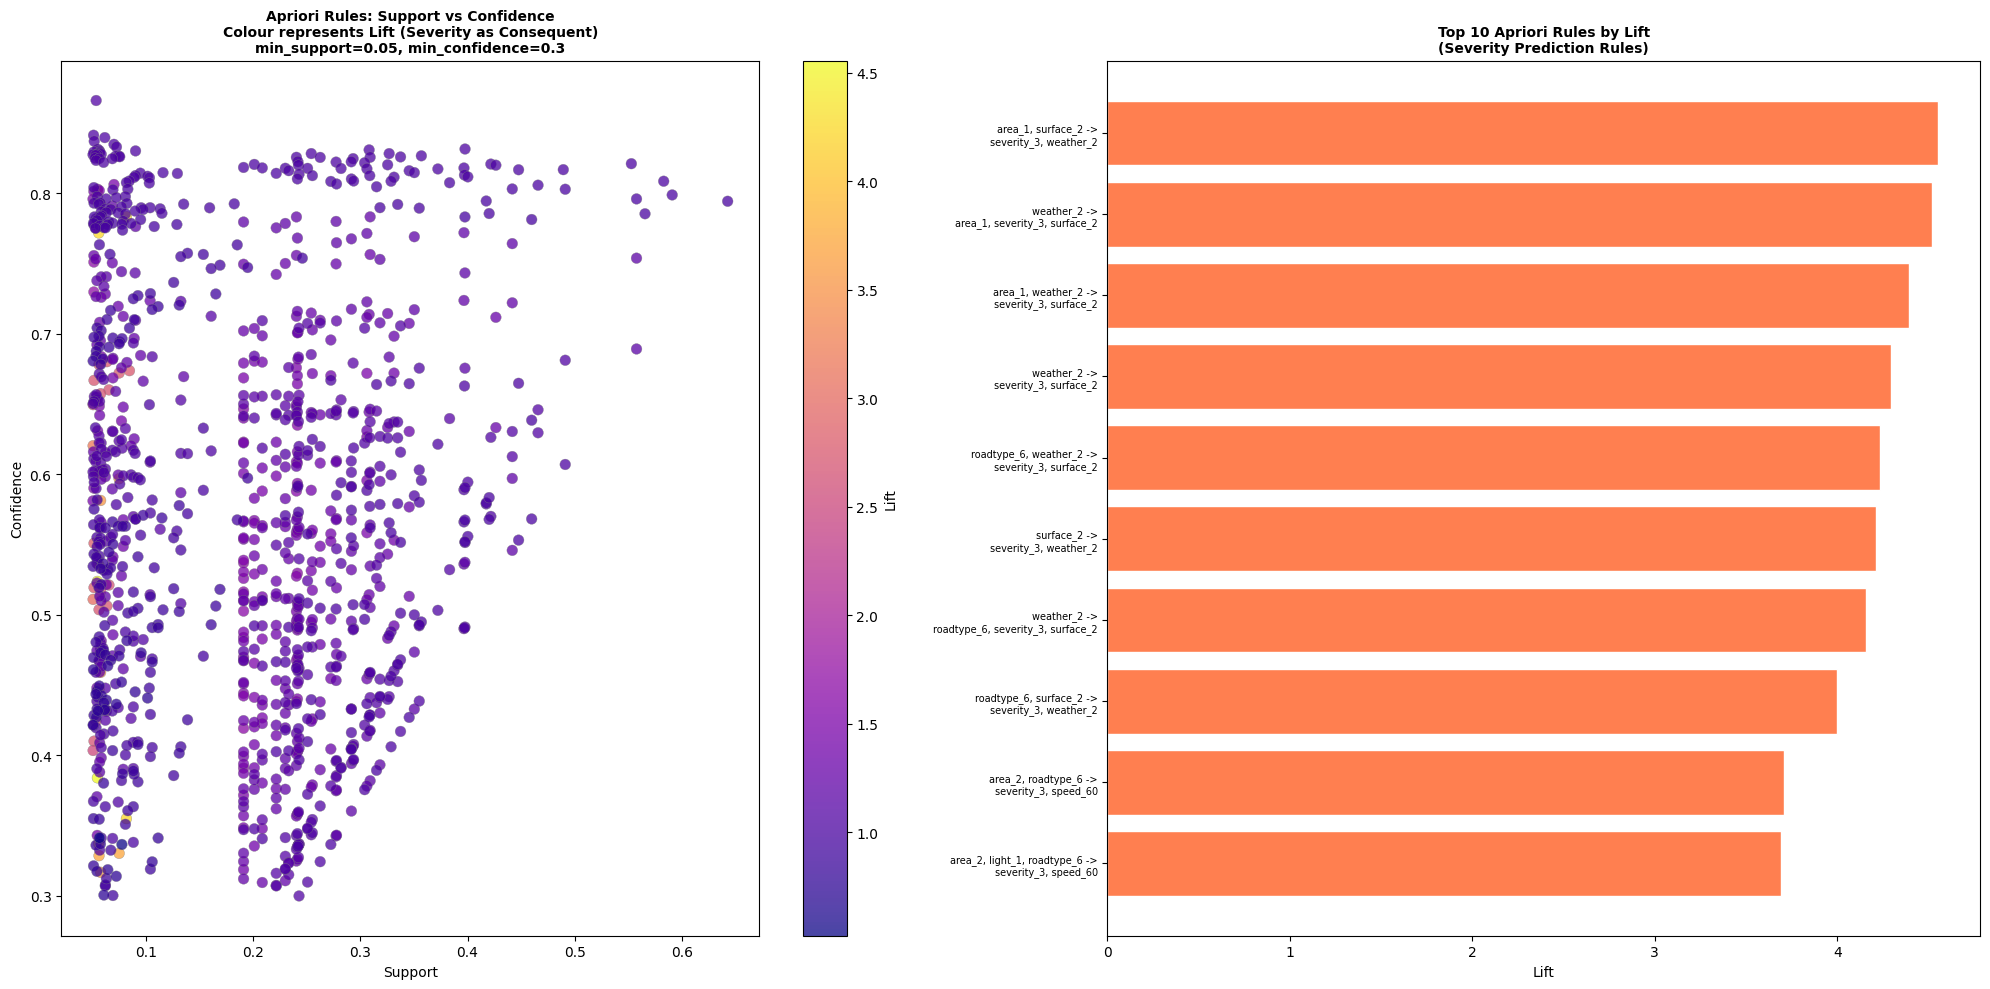

In [30]:
# Display top 15 severity rules from primary pass
# Lift > 1 indicates a stronger than chance relationship
display_primary = sev_rules.head(15)[['antecedents', 'consequents', 'support', 'confidence', 'lift']].copy()

# Convert frozensets into readable comma-separated strings
display_primary['antecedents'] = display_primary['antecedents'].apply(lambda x: ', '.join(sorted(x)))
display_primary['consequents'] = display_primary['consequents'].apply(lambda x: ', '.join(sorted(x)))

print('Top 15 rules predicting severity — primary pass (sorted by lift):')
print(display_primary.round(4).to_string(index=False))

# Display top 10 Fatal rules from secondary pass
display_fatal = fatal_rules.head(10)[['antecedents', 'consequents', 'support', 'confidence', 'lift']].copy()
display_fatal['antecedents'] = display_fatal['antecedents'].apply(lambda x: ', '.join(sorted(x)))
display_fatal['consequents'] = display_fatal['consequents'].apply(lambda x: ', '.join(sorted(x)))
print('\nTop 10 Fatal severity rules — secondary pass (min_support=0.005):')
print(display_fatal.round(4).to_string(index=False))

# Visualisation: Apriori Rule Strength
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Scatter Plot: Support vs Confidence coloured by Lift (primary severity rules)
scatter = axes[0].scatter(sev_rules['support'],
                          sev_rules['confidence'],
                          c=sev_rules['lift'],
                          cmap='plasma',
                          alpha=0.75,
                          s=60,
                          edgecolors='grey',
                          linewidths=0.3)

plt.colorbar(scatter, ax=axes[0], label='Lift')
axes[0].set_xlabel('Support')
axes[0].set_ylabel('Confidence')
axes[0].set_title(
    'Apriori Rules: Support vs Confidence\n'
    'Colour represents Lift (Severity as Consequent)\n'
    'min_support=0.05, min_confidence=0.3',
    fontsize=10,
    fontweight='bold'
)

# Bar Chart: Top 10 rules by Lift from primary pass
top10 = sev_rules.head(10).copy()

# Create readable rule labels (antecedent -> consequent)
top10['label'] = top10.apply(lambda r: ', '.join(sorted(r['antecedents']))[:50] + ' ->\n' + ', '.join(sorted(r['consequents'])),
                             axis=1)

axes[1].barh(top10['label'][::-1], # reversed so highest lift appears at top
             top10['lift'][::-1], # reversed to match label order
             color='coral',
             edgecolor='white')

axes[1].set_xlabel('Lift')
axes[1].set_title('Top 10 Apriori Rules by Lift\n(Severity Prediction Rules)',
                  fontsize=10,
                  fontweight='bold')
axes[1].tick_params(axis='y', labelsize=7)

# Adjust layout and display plots
plt.tight_layout()
plt.show()

##
## Task 5: Clustering of Road Accidents in West Yorkshire ('police_force == 13')

K-Means is applied on geographic coordinates and a multi-feature set (location, severity, speed, lighting). DBSCAN with Haversine distance identifies spatial accident hotspots. Both algorithms use silhouette-based hyperparameter tuning.

**Filter West Yorkshire 2018 Accidents and Impute Missing Values**

In [31]:
# West Yorkshire police force code (STATS19)
WY_FORCE = 13

# Filter dataset to West Yorkshire accidents only
wy = acc2018_raw[acc2018_raw['police_force'] == WY_FORCE].copy()

# Handle missing geographic data (latitude / longitude)
# Use median because it is robust to extreme spatial outliers
for col in ['latitude', 'longitude']:
    median_val = wy[col].median()
    missing = wy[col].isna().sum()

    wy[col] = wy[col].fillna(median_val)

    if missing > 0:
        print(f'Imputed {missing} missing values in {col} -> median ({median_val:.4f})')



# Handle categorical missing values (-1 = unknown in STATS19)
categorical_cols = ['speed_limit', 'weather_conditions', 
                    'light_conditions','road_surface_conditions', 
                    'urban_or_rural_area', 'road_type']

for col in categorical_cols:
    wy[col] = wy[col].replace(-1, np.nan)
    wy[col] = wy[col].fillna(wy[col].mode()[0])


# Summary statistics
print(f'West Yorkshire 2018 accidents: {len(wy):,}')
print(f'Latitude range: {wy["latitude"].min():.4f} – {wy["latitude"].max():.4f}')
print(f'Longitude range: {wy["longitude"].min():.4f} – {wy["longitude"].max():.4f}')

print('\nSeverity distribution:')
print(wy['accident_severity'].map({1: 'Fatal', 2: 'Serious', 3: 'Slight'}).value_counts())

West Yorkshire 2018 accidents: 4,132
Latitude range: 53.5397 – 53.9411
Longitude range: -2.1408 – -1.2290

Severity distribution:
accident_severity
Slight     3330
Serious     739
Fatal        63
Name: count, dtype: int64


###
**K-Means hyperparameter tuning**

k= 2, inertia=57.1378, silhouette=0.5035
k= 3, inertia=39.4272, silhouette=0.4704
k= 4, inertia=29.6978, silhouette=0.4511
k= 5, inertia=24.3577, silhouette=0.4510
k= 6, inertia=20.5048, silhouette=0.3955
k= 7, inertia=16.8090, silhouette=0.4377
k= 8, inertia=14.9083, silhouette=0.4351
k= 9, inertia=12.6445, silhouette=0.4528
k=10, inertia=11.6294, silhouette=0.4548


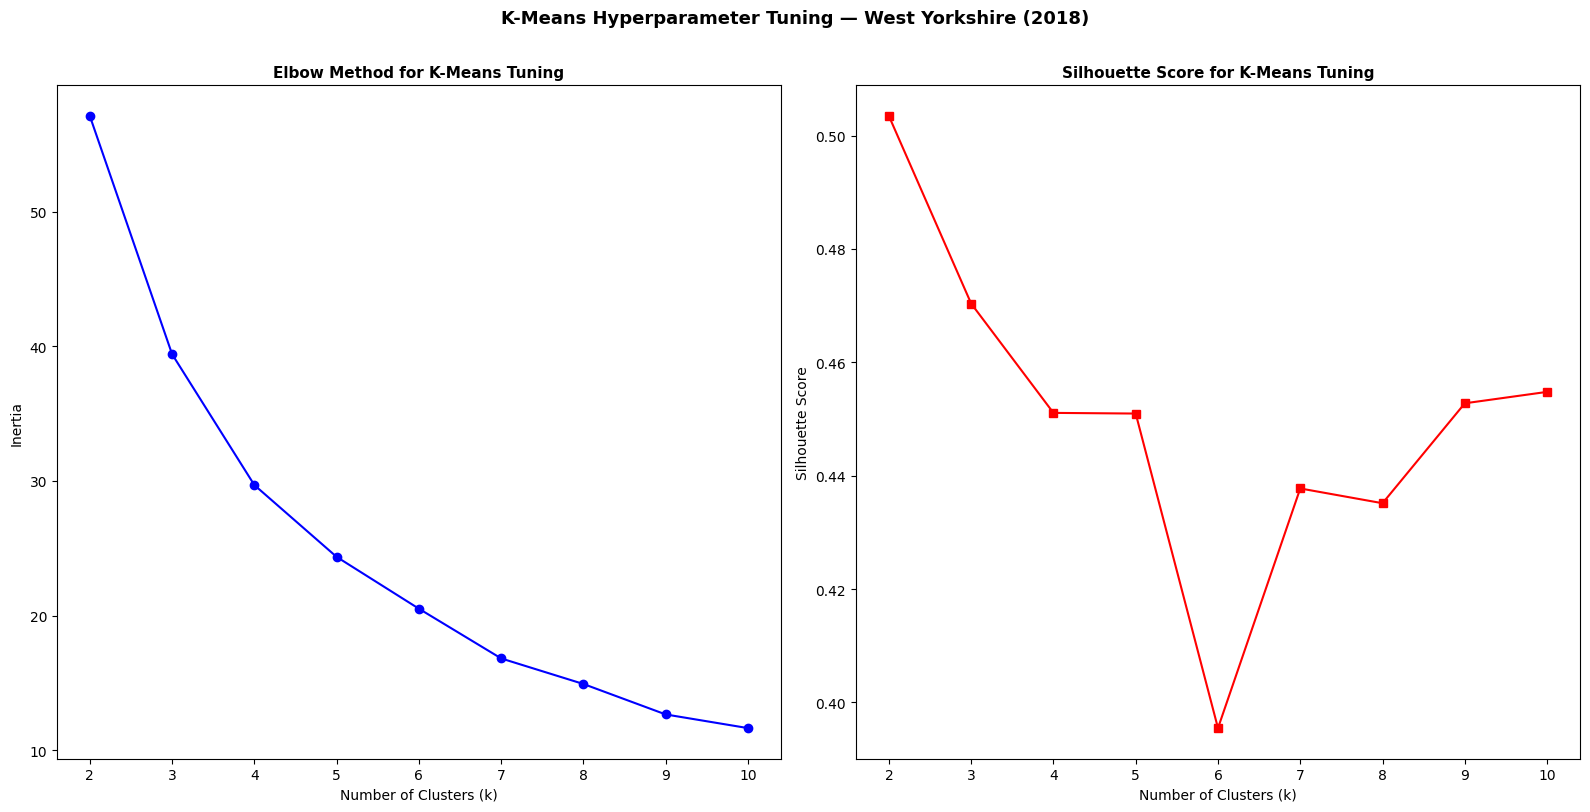


Optimal k (max silhouette): 2, score = 0.5035


In [32]:
# K-Means Hyperparameter Tuning (Elbow + Silhouette Method)

# Goal: Identify optimal number of clusters (k) using:
#   - Elbow method (inertia)
#   - Silhouette score (cluster quality: higher = better separation)


# Prepare geographic feature matrix (latitude / longitude)
X_geo = wy[['latitude', 'longitude']].values

K_RANGE = range(2, 11)
inertias = []
sil_scores = []

# Fit K-Means for different values of k
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init='auto')
    km.fit(X_geo)

    # Store inertia
    inertias.append(km.inertia_)

    # Compute silhouette score
    score = silhouette_score(X_geo, km.labels_)
    sil_scores.append(score)

    print(f'k={k:2d}, inertia={km.inertia_:.4f}, silhouette={score:.4f}')


# Visualisation: Elbow + Silhouette Analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 8))


# Elbow Method: Inertia vs k
axes[0].plot(list(K_RANGE), inertias, 'bo-', markersize=6)
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method for K-Means Tuning',
                  fontsize=11, 
                  fontweight='bold')
axes[0].set_xticks(list(K_RANGE))


# Silhouette Score: Cluster quality vs k
axes[1].plot(list(K_RANGE), sil_scores, 'rs-', markersize=6)
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score for K-Means Tuning',
                  fontsize=11, 
                  fontweight='bold')
axes[1].set_xticks(list(K_RANGE))



# Final layout and save figure
plt.suptitle('K-Means Hyperparameter Tuning — West Yorkshire (2018)',
             fontsize=13, fontweight='bold', y=1.01)

# Adjust layout and display plot
plt.tight_layout()
plt.show()


# Select optimal k (highest silhouette score)
best_k = list(K_RANGE)[sil_scores.index(max(sil_scores))]

print(f'\nOptimal k (max silhouette): {best_k}, score = {max(sil_scores):.4f}')

###
**K-Means: Fit Optimal k and Visualise Geographic Clusters**

K-Means (k=2) cluster sizes:
km_cluster
0    1986
1    2146
Name: count, dtype: int64


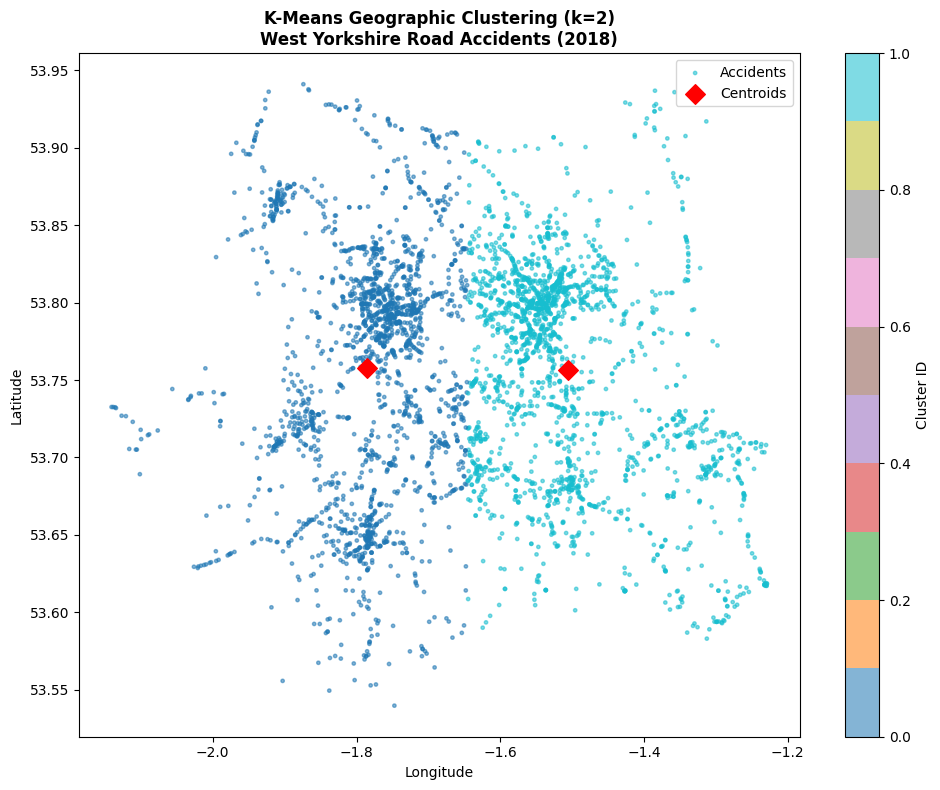


K-Means cluster severity profile:
            size  avg_severity  pct_fatal  pct_serious  avg_speed
km_cluster                                                       
0           1986          2.80       1.41        16.87      33.47
1           2146          2.78       1.63        18.83      36.12


In [33]:
OPTIMAL_K = best_k

km_opt = KMeans(n_clusters=OPTIMAL_K, random_state=RANDOM_STATE, n_init='auto')

# Assign cluster labels to each accident
wy['km_cluster'] = km_opt.fit_predict(X_geo)

# Extract cluster centroids (geographic centres)
centroids = km_opt.cluster_centers_

# Display cluster sizes
print(f'K-Means (k={OPTIMAL_K}) cluster sizes:')
print(wy['km_cluster'].value_counts().sort_index())


# Visualisation: Geographic Clusters
fig, ax = plt.subplots(figsize=(10, 8))

# Plot accident locations coloured by cluster
scatter = ax.scatter(wy['longitude'], 
                     wy['latitude'],
                     c=wy['km_cluster'],
                     cmap='tab10',
                     s=6,
                     alpha=0.55,
                     label='Accidents')

# Plot cluster centroids
ax.scatter(centroids[:, 1], # longitude
           centroids[:, 0], # latitude
           c='red',
           marker='D',
           s=100,
           zorder=5,
           label='Centroids')

# Add colour bar and labels
plt.colorbar(scatter, ax=ax, label='Cluster ID')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# Title for report
ax.set_title(
    f'K-Means Geographic Clustering (k={OPTIMAL_K})\n'
    f'West Yorkshire Road Accidents (2018)',
    fontsize=12,
    fontweight='bold'
)

ax.legend()

# Adjust layout and display
plt.tight_layout()
plt.show()


# Cluster Severity Profile
# Summarise each cluster to understand risk differences

profile_km = wy.groupby('km_cluster').agg(size=('accident_severity', 'count'), # total accidents
                                          avg_severity=('accident_severity', 'mean'), # average severity score
                                          pct_fatal=('accident_severity', lambda x: (x == 1).mean()*100),
                                          pct_serious=('accident_severity', lambda x: (x == 2).mean()*100),
                                          avg_speed=('speed_limit', 'mean')).round(2)

print('\nK-Means cluster severity profile:')
print(profile_km.to_string())

###
**K-Means: Multi-Feature Clustering**

k=2, silhouette=0.2470
k=3, silhouette=0.3364
k=4, silhouette=0.2531
k=5, silhouette=0.2917
k=6, silhouette=0.2781
k=7, silhouette=0.2829

Optimal k (multi-feature): 3, score = 0.3364

Multi-feature cluster profile:
                  size  avg_severity  pct_fatal  pct_serious  avg_speed  avg_light
km_multi_cluster                                                                  
0                 2939          3.00       0.00         0.00      30.82       1.87
1                  726          1.91       8.54        91.46      32.11       1.94
2                  467          2.84       0.21        16.06      64.45       2.30


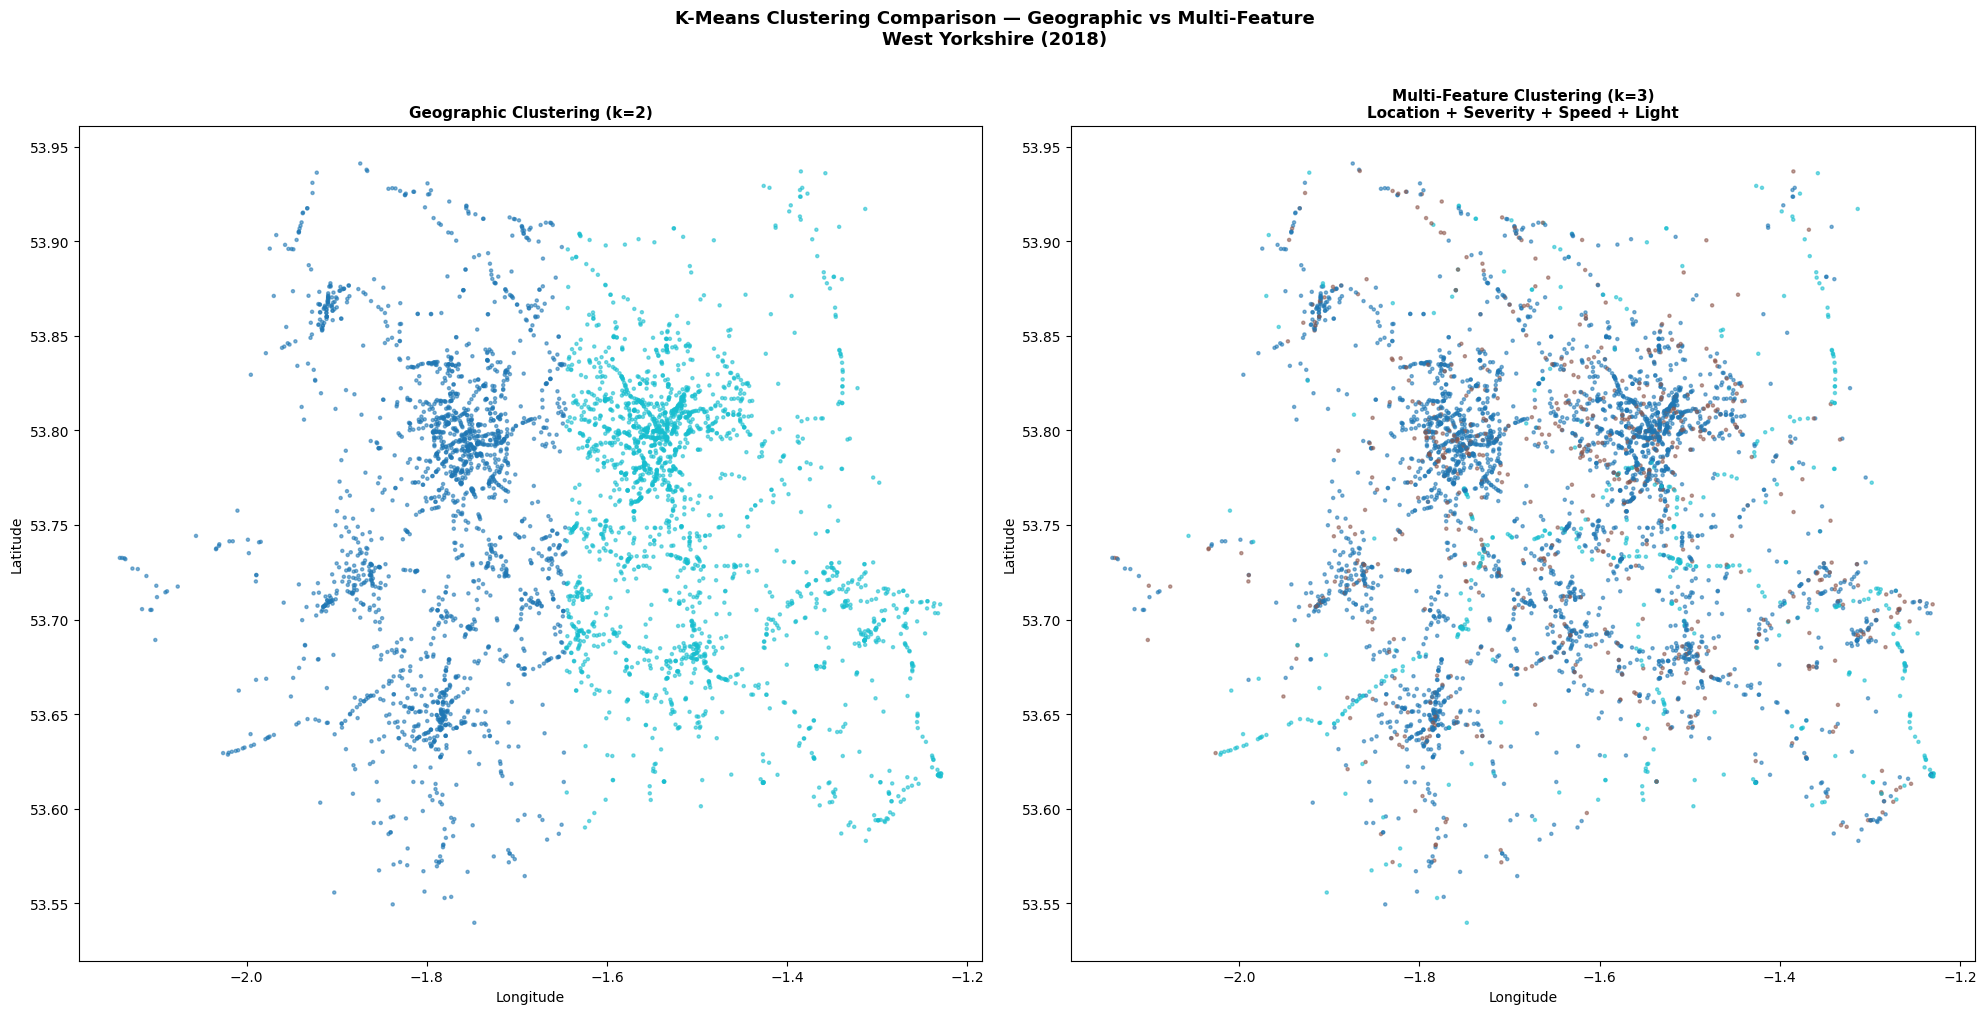

In [34]:
# Adds accident characteristics to geographic coordinates to reveal clusters defined by WHERE accidents happen AND under WHAT CONDITIONS
# Use multiple features (location + severity + conditions)
# StandardScaler ensures all variables contribute equally

FEATURES = ['latitude', 'longitude', 
            'accident_severity', 'speed_limit', 
            'light_conditions']

X_multi = StandardScaler().fit_transform(wy[FEATURES])


# Select optimal k using silhouette score
k_range = range(2, 8)
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init='auto')
    labels = km.fit_predict(X_multi)

    score = silhouette_score(X_multi, labels)
    sil_scores.append(score)

    print(f'k={k}, silhouette={score:.4f}')

# Best k = highest silhouette score
best_k_multi = list(k_range)[sil_scores.index(max(sil_scores))]

print(f'\nOptimal k (multi-feature): {best_k_multi}, score = {max(sil_scores):.4f}')



# Fit final model with optimal k
km_multi = KMeans(n_clusters=best_k_multi, random_state=RANDOM_STATE, n_init='auto')
wy['km_multi_cluster'] = km_multi.fit_predict(X_multi)

# Cluster profiling (understand cluster characteristics)
profile_multi = wy.groupby('km_multi_cluster').agg(
    size=('accident_severity', 'count'), # number of accidents
    avg_severity=('accident_severity', 'mean'), # average severity
    pct_fatal=('accident_severity', lambda x: (x == 1).mean()*100),
    pct_serious=('accident_severity', lambda x: (x == 2).mean()*100),
    avg_speed=('speed_limit', 'mean'), # average speed limit
    avg_light=('light_conditions', 'mean') # average light condition
).round(2)

print('\nMulti-feature cluster profile:')
print(profile_multi.to_string())


# Visual comparison: Geographic vs Multi-feature clustering
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Geographic-only clustering
axes[0].scatter(wy['longitude'], 
                wy['latitude'],
                c=wy['km_cluster'], 
                cmap='tab10',
                s=5, alpha=0.55)

axes[0].set_title(f'Geographic Clustering (k={OPTIMAL_K})',
                  fontsize=11, fontweight='bold')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')

# Multi-feature clustering
axes[1].scatter(wy['longitude'], 
                wy['latitude'],
                c=wy['km_multi_cluster'], 
                cmap='tab10',
                s=5, alpha=0.55)
axes[1].set_title(
    f'Multi-Feature Clustering (k={best_k_multi})\n'
    'Location + Severity + Speed + Light',
    fontsize=11, fontweight='bold'
)
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')


# Final layout and save
plt.suptitle(
    'K-Means Clustering Comparison — Geographic vs Multi-Feature\n'
    'West Yorkshire (2018)',
    fontsize=13, fontweight='bold', y=1.01
)

# Adjust layout and display plot
plt.tight_layout()
plt.show()

###
**DBSCAN Hyperparameter Tuning**

In [35]:
# DBSCAN Hyperparameter Tuning (Grid Search)
# Use Haversine distance (correct for geographic coordinates)

# Convert latitude/longitude to radians
coords = np.radians(wy[['latitude', 'longitude']].values)


# Define parameter grid
eps_values = [0.5, 0.8, 1.0, 1.2, 1.5] # radius in km
min_samples_values = [3, 5, 8, 10] # minimum points per cluster

print('DBSCAN Hyperparameter Tuning')
print('eps (km) | min_samples | clusters | noise % | silhouette')

results = [] # store results for comparison


# Grid search over parameter combinations
for eps_km, min_s in product(eps_values, min_samples_values):

    # Convert eps from kilometres to radians (Earth radius ≈ 6371 km)
    eps_rad = eps_km / 6371.0

    # Fit DBSCAN using Haversine distance for geographic accuracy
    db = DBSCAN(eps=eps_rad,
                min_samples=min_s,
                metric='haversine',
                algorithm='ball_tree')

    labels = db.fit_predict(coords)

    # Number of clusters (excluding noise label = -1)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    # Percentage of noise points
    noise_pct = (labels == -1).sum() / len(labels) * 100

    # Silhouette score (only for clustered points)
    mask = labels != -1
    if n_clusters > 1 and mask.sum() > 1:
        sil = silhouette_score(coords[mask], labels[mask])
        sil_str = f'{sil:.4f}'
    else:
        sil = np.nan
        sil_str = 'N/A'

    # Print results
    print(f'{eps_km:<10} {min_s:<12} {n_clusters:<10} {noise_pct:<10.1f} {sil_str:<10}')

    # Store results
    results.append({
        'eps_km': eps_km,
        'min_samples': min_s,
        'n_clusters': n_clusters,
        'noise_pct': round(noise_pct, 1),
        'silhouette': round(sil, 4) if not np.isnan(sil) else np.nan
    })


# Select best parameters (highest silhouette score)
results_df = pd.DataFrame(results).dropna(subset=['silhouette']) # Convert results to DataFrame and remove invalid silhouette scores
best = results_df.loc[results_df['silhouette'].idxmax()] # Identify best parameter combination

# Display optimal settings
print(f'\nBest parameters (silhouette = {best["silhouette"]:.4f}):')
print(f'eps = {best["eps_km"]} km')
print(f'min_samples = {int(best["min_samples"])}')
print(f'clusters = {int(best["n_clusters"])}')
print(f'noise = {best["noise_pct"]}%')


# Store best parameters for use in final DBSCAN model
BEST_EPS_KM = best['eps_km']
BEST_MIN_SAMPLES = int(best['min_samples'])

DBSCAN Hyperparameter Tuning
eps (km) | min_samples | clusters | noise % | silhouette
0.5        3            193        13.8       0.0855    
0.5        5            115        24.6       0.1477    
0.5        8            70         40.7       0.1729    
0.5        10           47         49.5       0.2381    
0.8        3            93         5.4        -0.3341   
0.8        5            61         10.0       -0.0249   
0.8        8            47         17.0       0.2181    
0.8        10           33         25.0       0.2842    
1.0        3            63         3.4        -0.4301   
1.0        5            53         6.0        -0.2758   
1.0        8            30         11.8       -0.2144   
1.0        10           21         16.9       -0.1501   
1.2        3            39         2.2        -0.4532   
1.2        5            33         3.8        -0.3956   
1.2        8            25         8.3        -0.2933   
1.2        10           19         11.5       -0.1960   
1.

###
**DBSCAN: Fit with Tuned Parameters**

In [36]:
# Use best parameters identified from grid search
EPS_KM = BEST_EPS_KM
MIN_SAMPLES = BEST_MIN_SAMPLES

# Convert eps from kilometres to radians (required for Haversine distance)
EPS_RAD = EPS_KM / 6371.0

# Fit DBSCAN model using optimal parameters
db = DBSCAN(eps=EPS_RAD,
            min_samples=MIN_SAMPLES,
            algorithm='ball_tree', # efficient for spatial data
            metric='haversine') # accurate distance for lat/lon coordinates

# Assign cluster labels to dataset (-1 = noise / outliers)
wy['dbscan_cluster'] = db.fit_predict(coords)


# Summary statistics: cluster structure

# Number of clusters (excluding noise label = -1)
n_clusters_db = len(set(wy['dbscan_cluster'])) - 1

# Number of noise (unclustered) points
n_noise = (wy['dbscan_cluster'] == -1).sum()

print(f'DBSCAN final results (tuned: eps = {EPS_KM}km, min_samples={MIN_SAMPLES}):')
print(f'Accident hotspots identified: {n_clusters_db}')
print(f'Noise points (isolated): {n_noise} ({n_noise/len(wy)*100:.1f}%)')
print(f'Clustered accidents: {len(wy)-n_noise:,} '
      f'({(len(wy)-n_noise)/len(wy)*100:.1f}%)')


# Cluster severity profile (exclude noise)

# Separate clustered points from noise
noise_mask   = wy['dbscan_cluster'] == -1
cluster_mask = ~noise_mask

# Aggregate key severity metrics for each cluster
profile_db = wy[cluster_mask].groupby('dbscan_cluster').agg(
    size=('accident_severity', 'count'), # cluster size
    avg_severity=('accident_severity', 'mean'), # average severity score
    pct_fatal=('accident_severity', lambda x: (x == 1).mean() * 100),
    pct_serious=('accident_severity', lambda x: (x == 2).mean() * 100),
    pct_slight=('accident_severity', lambda x: (x == 3).mean() * 100)
).sort_values('size', ascending=False)

# Display largest clusters (hotspots)
print(f'\nTop 10 hotspot clusters by size:')
print(profile_db.head(10).round(2).to_string())

DBSCAN final results (tuned: eps = 0.8km, min_samples=10):
Accident hotspots identified: 33
Noise points (isolated): 1033 (25.0%)
Clustered accidents: 3,099 (75.0%)

Top 10 hotspot clusters by size:
                size  avg_severity  pct_fatal  pct_serious  pct_slight
dbscan_cluster                                                        
0               1018          2.80       1.18        17.78       81.04
7                744          2.84       0.81        14.38       84.81
3                198          2.86       0.51        13.13       86.36
9                156          2.81       1.92        15.38       82.69
12               127          2.80       1.57        17.32       81.10
13               127          2.81       1.57        15.75       82.68
6                 78          2.81       1.28        16.67       82.05
4                 72          2.82       1.39        15.28       83.33
23                64          2.70       1.56        26.56       71.88
8                 54

###
**DBSCAN: Visualise Hotspots and Severity Profile**

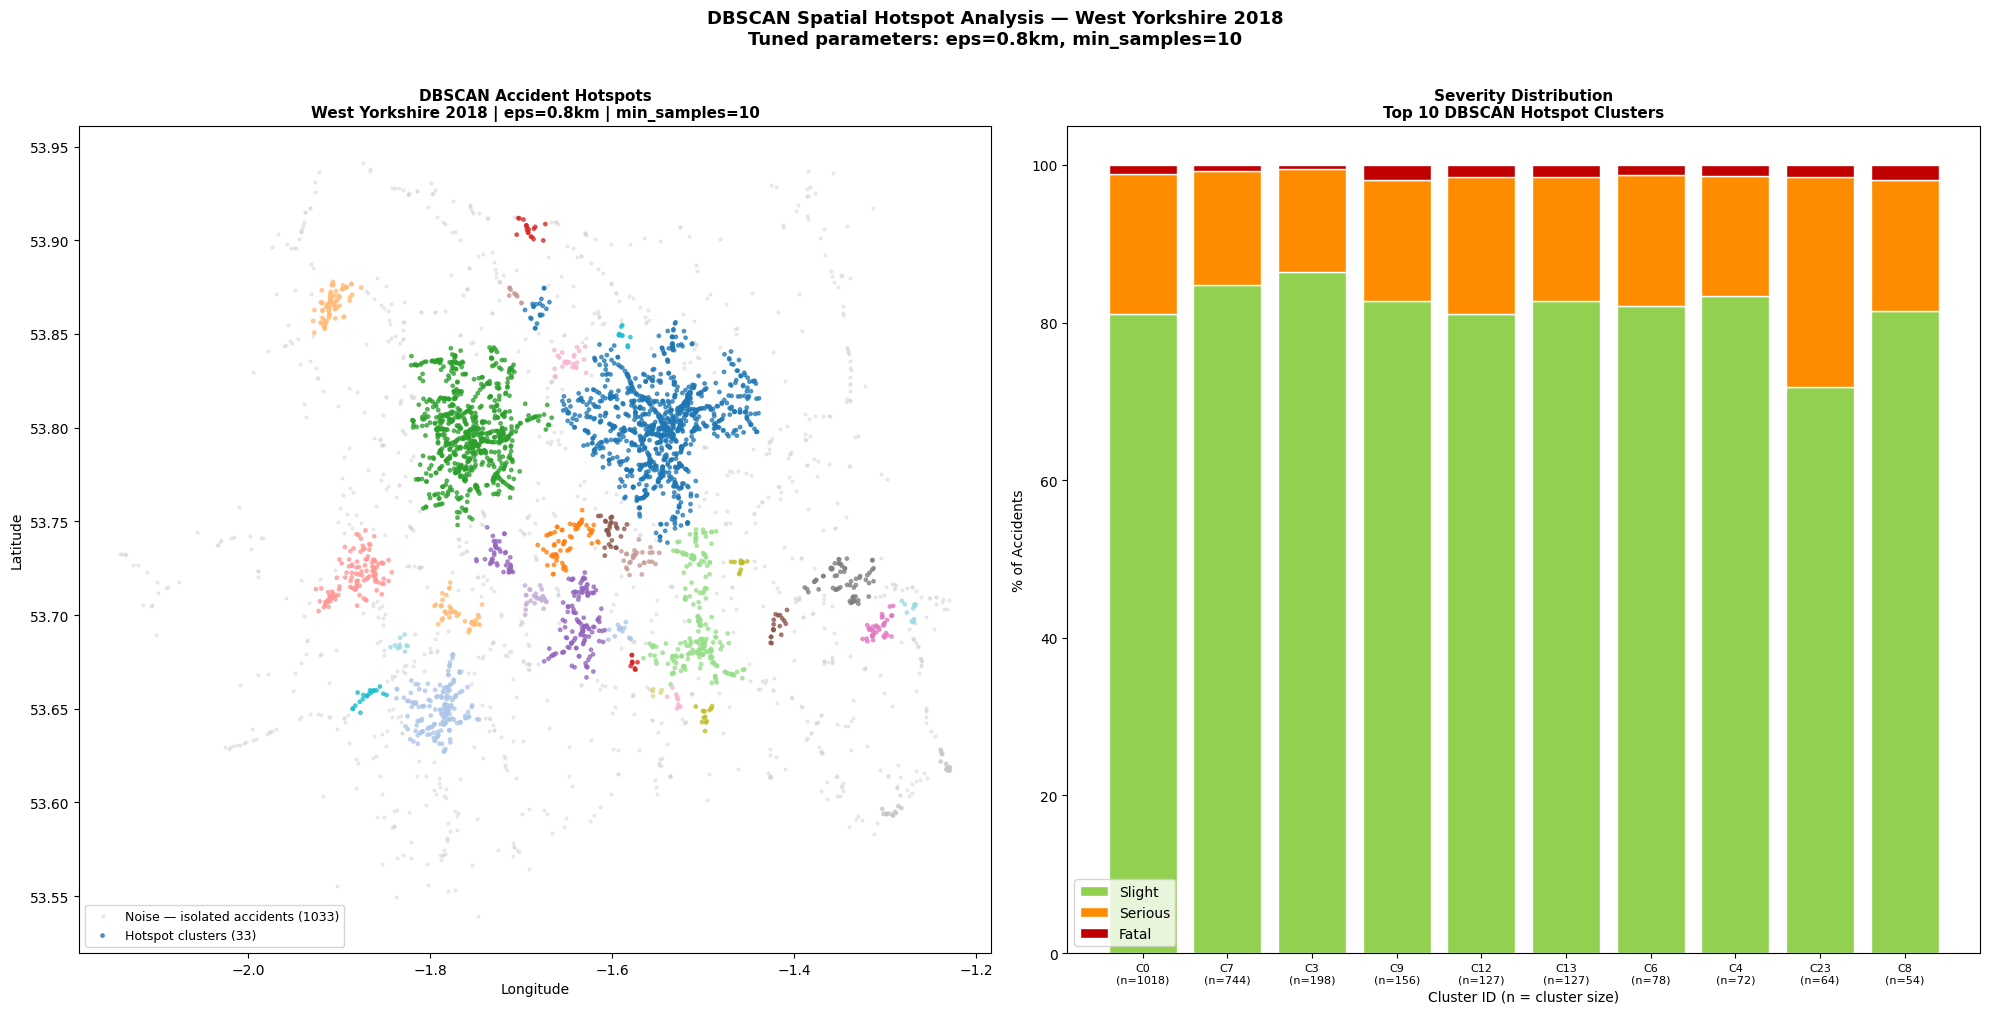

In [37]:
# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(20, 10))


# Left Plot: Geographic Distribution of DBSCAN Clusters

# Grey points = noise (isolated accidents not assigned to any cluster)
# Coloured points = detected hotspot clusters

axes[0].scatter(wy.loc[noise_mask, 'longitude'],
                wy.loc[noise_mask, 'latitude'],
                c='lightgrey', s=4, alpha=0.4,
                label=f'Noise — isolated accidents ({n_noise})')

axes[0].scatter(wy.loc[cluster_mask, 'longitude'],
                wy.loc[cluster_mask, 'latitude'],
                c=wy.loc[cluster_mask, 'dbscan_cluster'], # colour by cluster ID
                cmap='tab20', s=6, alpha=0.7,
                label=f'Hotspot clusters ({n_clusters_db})')

# Axis labels and title
axes[0].set_title(
    f'DBSCAN Accident Hotspots\n'
    f'West Yorkshire 2018 | eps={EPS_KM}km | min_samples={MIN_SAMPLES}',
    fontsize=11, fontweight='bold'
)
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].legend(fontsize=9)


# Right Plot: Severity Distribution for Top 10 Clusters
# Select largest clusters (by number of accidents)
top10_db = profile_db.head(10)

# X positions for bars
x_pos = range(len(top10_db))

# Stacked bar chart: Slight -> Serious -> Fatal
axes[1].bar(x_pos,
            top10_db['pct_slight'],
            label='Slight',
            color='#92D050',
            edgecolor='white')

axes[1].bar(x_pos,
            top10_db['pct_serious'],
            bottom=top10_db['pct_slight'],
            label='Serious',
            color='#FF8C00',
            edgecolor='white')

axes[1].bar(x_pos,
            top10_db['pct_fatal'],
            bottom=top10_db['pct_slight'] + top10_db['pct_serious'],
            label='Fatal',
            color='#C00000',
            edgecolor='white')

# Label clusters as C0, C1, etc, and include size (n)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(
    [f'C{i}\n(n={v})' for i, v in zip(top10_db.index, top10_db['size'])],
    fontsize=8
)

# Axis labels and title
axes[1].set_xlabel('Cluster ID (n = cluster size)')
axes[1].set_ylabel('% of Accidents')
axes[1].set_title('Severity Distribution\nTop 10 DBSCAN Hotspot Clusters',
                  fontsize=11,
                  fontweight='bold')

axes[1].legend()

# Overall figure formatting and export
plt.suptitle(
    'DBSCAN Spatial Hotspot Analysis — West Yorkshire 2018\n'
    f'Tuned parameters: eps={EPS_KM}km, min_samples={MIN_SAMPLES}',
    fontsize=13,
    fontweight='bold',
    y=1.01
)

# Adjust layout and display plot
plt.tight_layout()
plt.show()

##
## Task 6: Time Series Forecasting - Weekly Accident Counts (3 Policing Areas)

**Selected policing areas:** Metropolitan Police (code 1), West Midlands (code 20), West Yorkshire (code 13)
**Training:** 2017–2018 (105 weeks); **Forecast target:** 2019 (52 weeks)

Three models are compared: Holt-Winters (grid search tuning), SARIMA (validation-based order selection), and XGBoost (GridSearchCV). STL decomposition and ADF test are applied before modelling.

In [38]:
# Load accident data for 3 years
acc_3yr = load_accidents([2017, 2018, 2019])

# Impute missing values to ensure consistent dataset
acc_3yr = impute_accidents(acc_3yr)

# Convert date column to datetime format which is required for time-based grouping
acc_3yr['date'] = pd.to_datetime(acc_3yr['date'], dayfirst=True, errors='coerce')


# Define the police forces to analyse
TASK6_FORCES = {
    1:  'Metropolitan Police',
    20: 'West Midlands',
    13: 'West Yorkshire'
}

# Function to build weekly time series for a given police force
def build_weekly_series(df, force_code):
    # Convert accident records into a weekly time series.
    
    # Filter to selected police force and remove invalid dates
    sub = df[df['police_force'] == force_code].dropna(subset=['date']).copy()

    # Convert each date to its corresponding week start (Monday)
    sub['week'] = sub['date'].dt.to_period('W').apply(lambda p: p.start_time)

    # Aggregate: count accidents per week
    weekly = sub.groupby('week').size()

    # Ensure datetime index and fill missing weeks with 0
    weekly.index = pd.DatetimeIndex(weekly.index)
    return weekly.asfreq('W-MON', fill_value=0)


# Summary of training and testing splits
print(f'Loaded {len(acc_3yr):,} records (2017–2019)')

for code, name in TASK6_FORCES.items():
    
    # Build weekly time series
    w = build_weekly_series(acc_3yr, code)
    
    # Split into training (2017–2018) and testing (2019)
    train = w.loc['2017':'2018']
    test  = w.loc['2019']
    
    # Display dataset statistics
    print(f'{name}: {len(train)} training weeks, {len(test)} test weeks ; '
          f'mean={train.mean():.1f}, std={train.std():.1f}')

Imputed 112 missing latitude values
Imputed 112 missing longitude values
Loaded 370,153 records (2017–2019)
Metropolitan Police: 105 training weeks, 52 test weeks ; mean=498.5, std=65.0
West Midlands: 105 training weeks, 52 test weeks ; mean=106.8, std=16.8
West Yorkshire: 105 training weeks, 52 test weeks ; mean=81.2, std=13.9


###
**STL Decomposition**

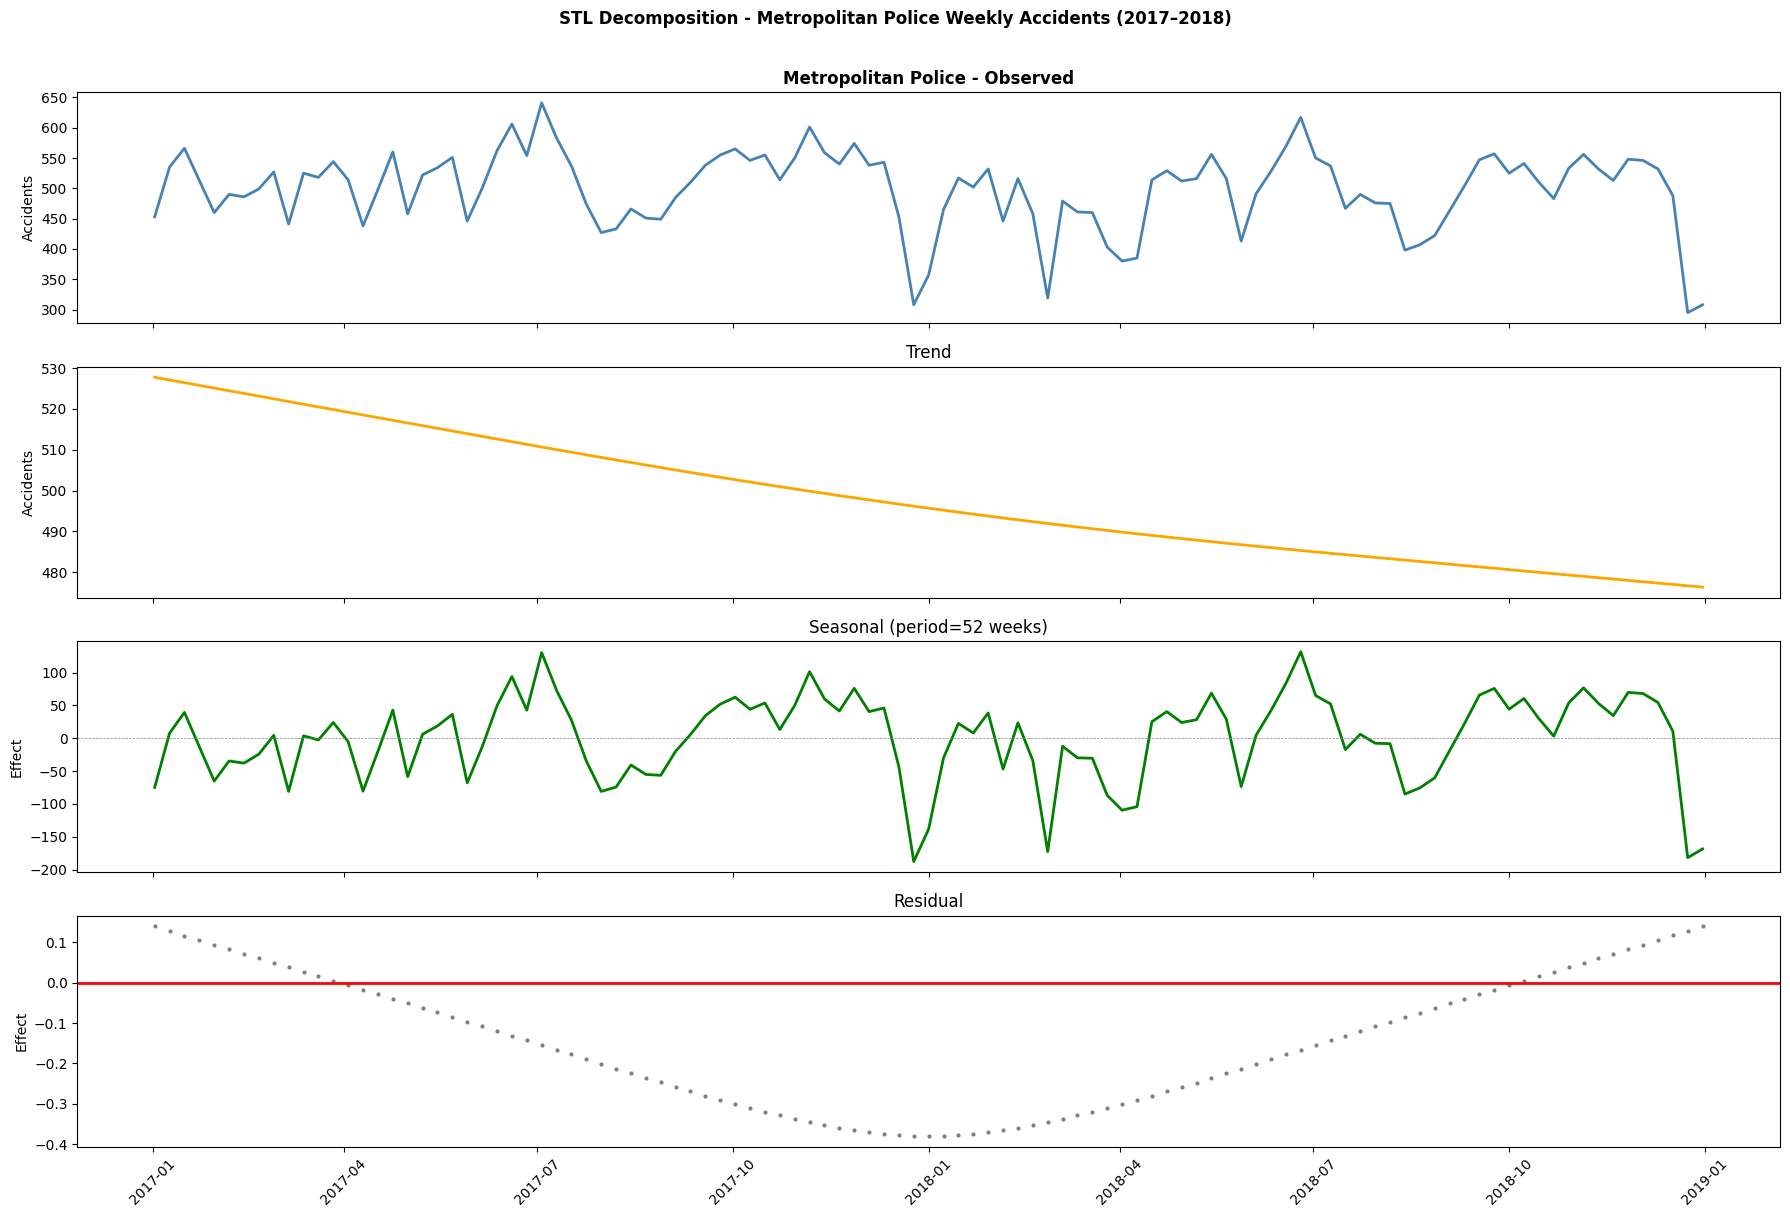

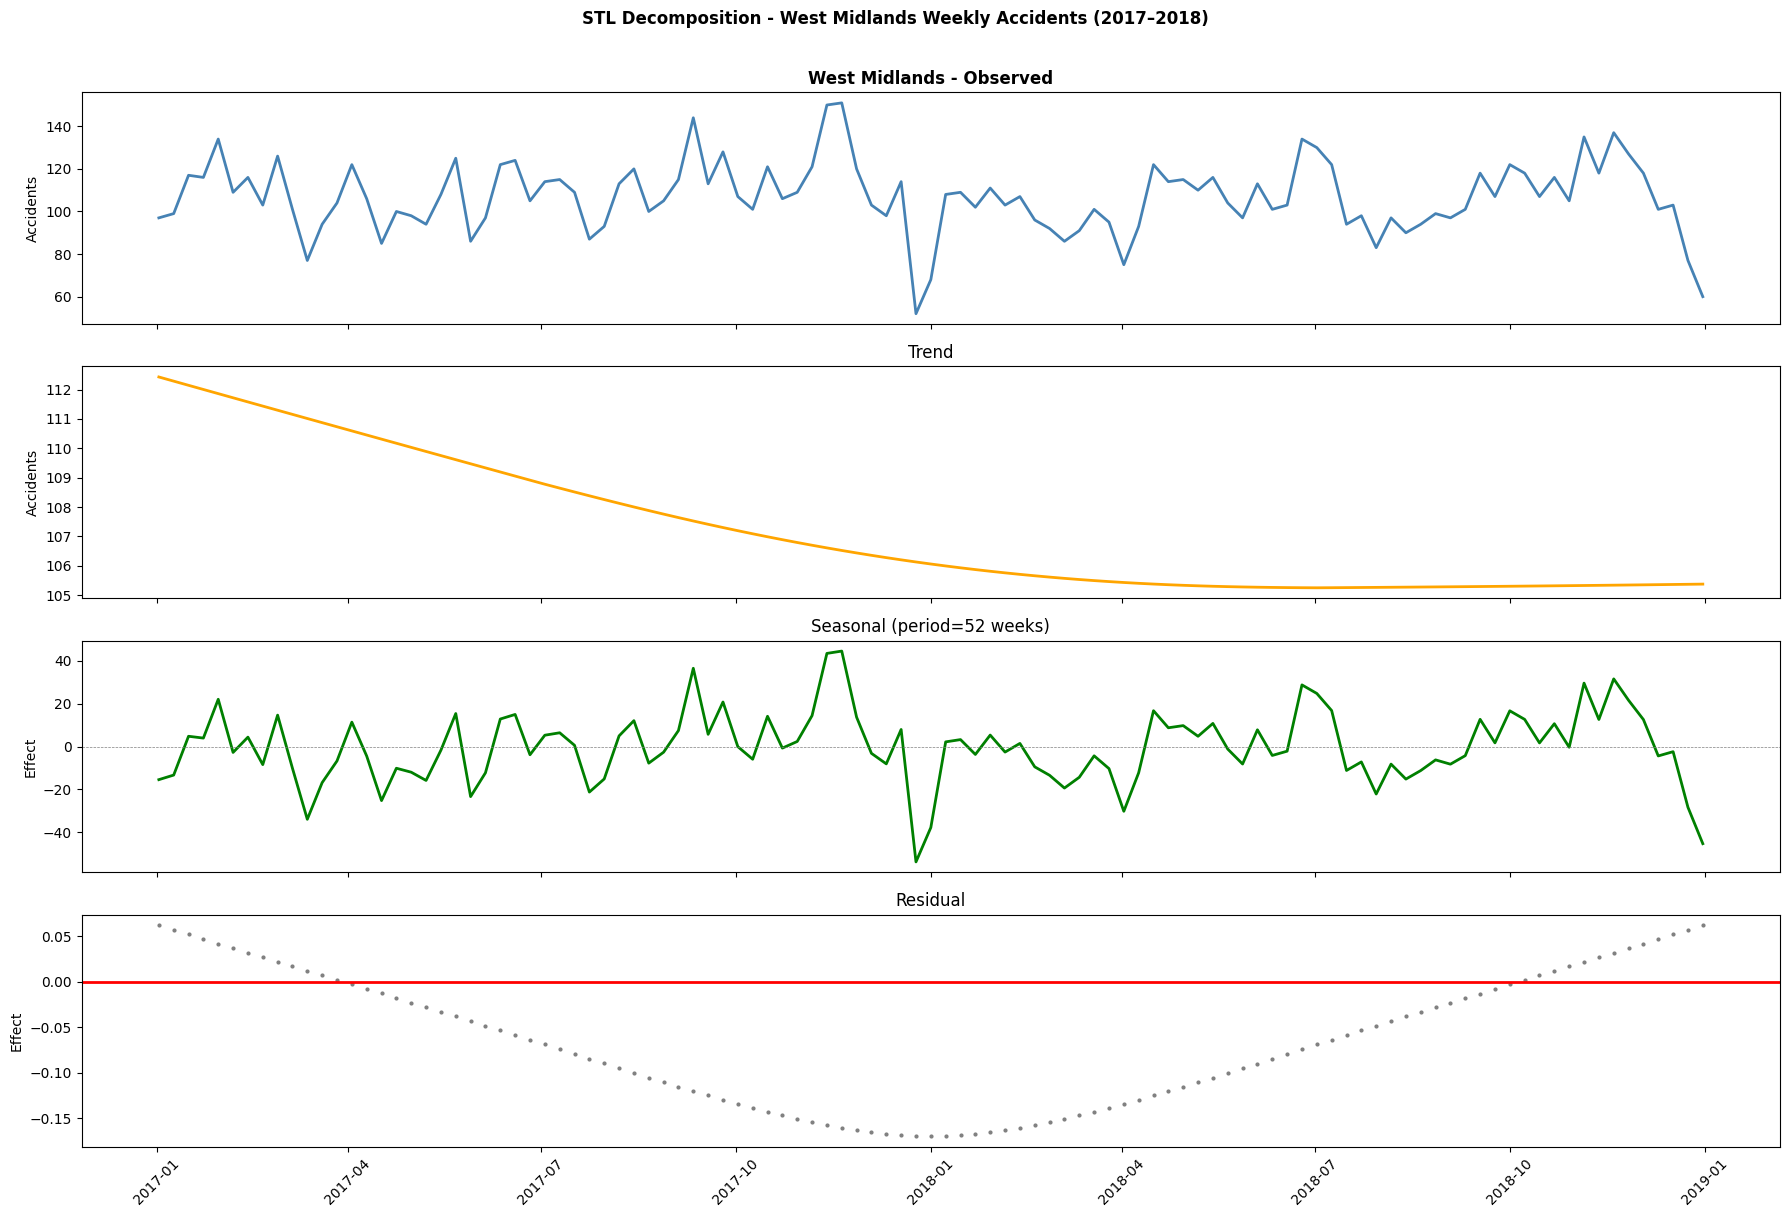

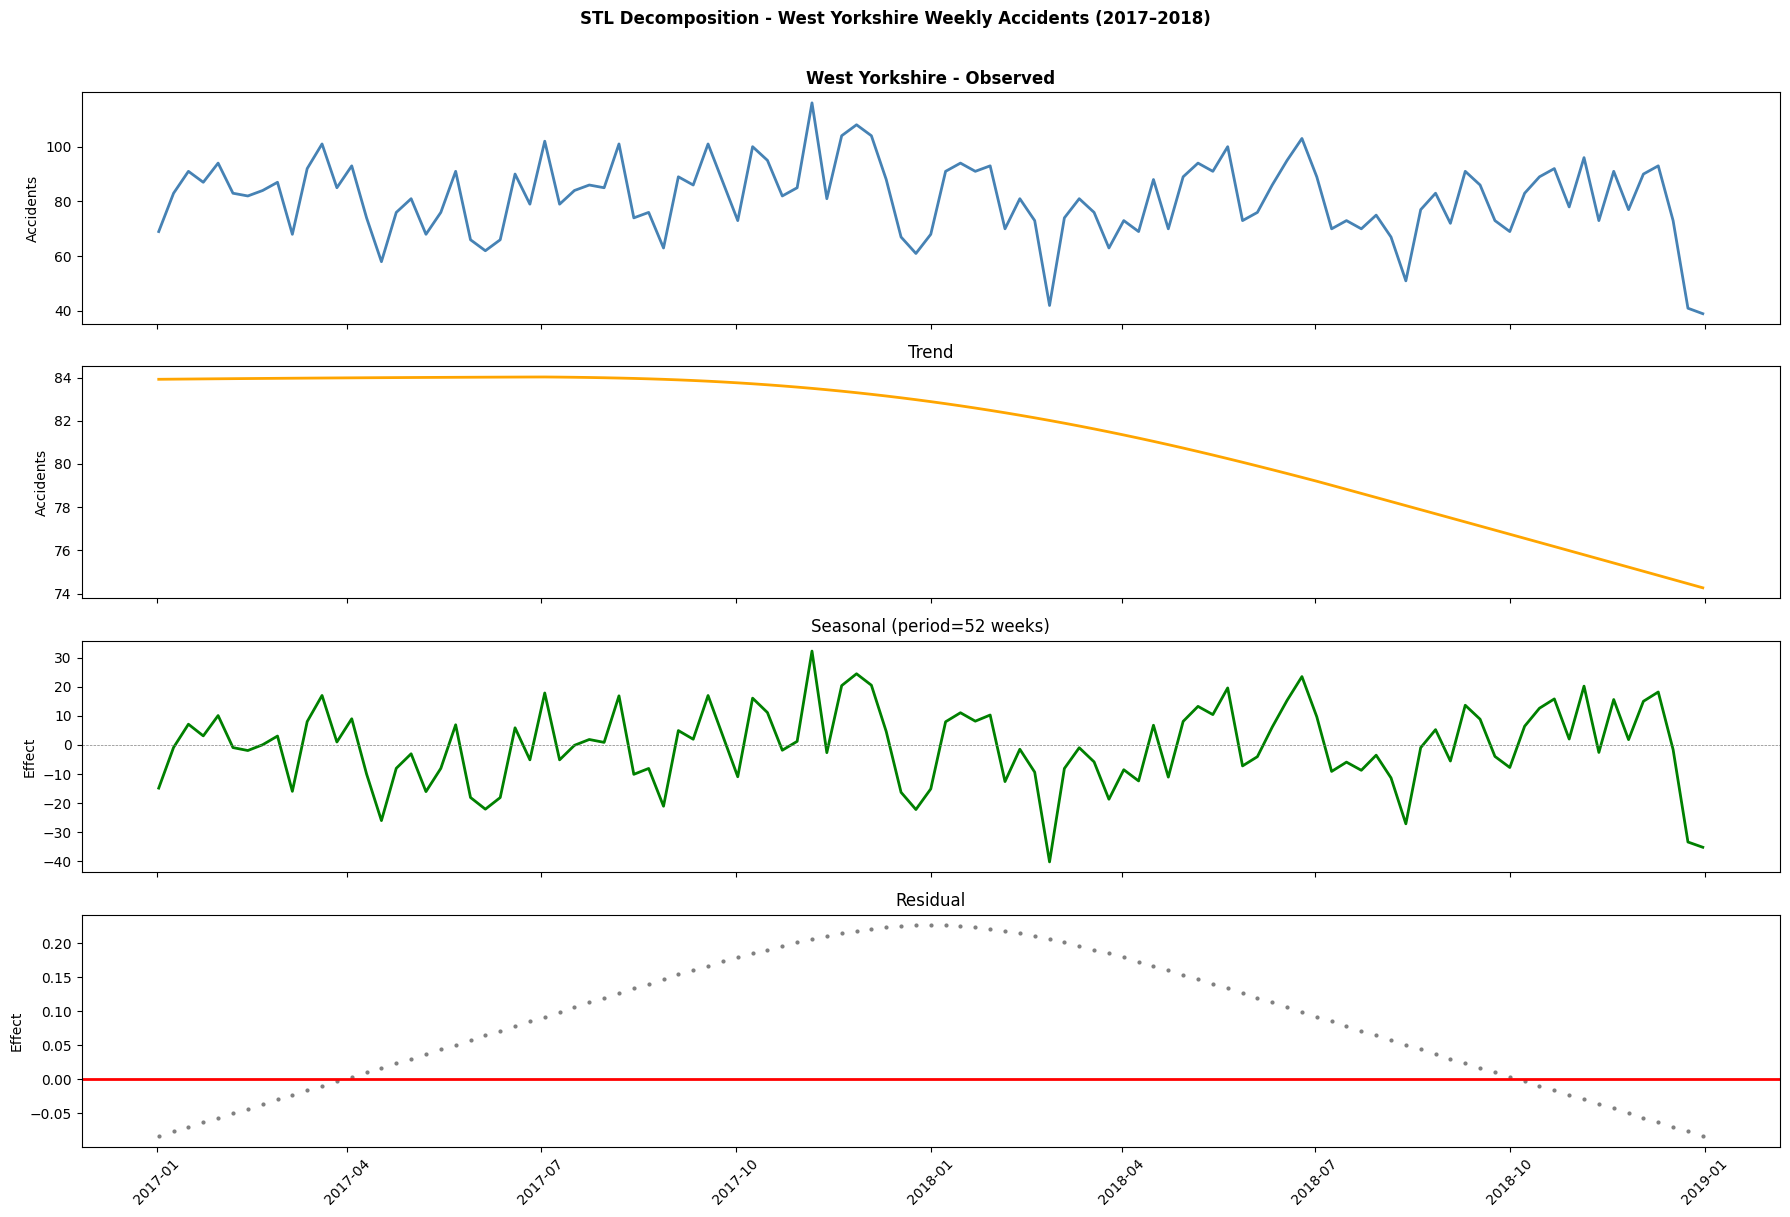

In [39]:
# Task 6 — STL Decomposition (Trend, Seasonality, Residuals)
"""
Decomposes each weekly time series into:
- Trend: long-term movement in accident counts
- Seasonal: repeating yearly pattern (52 weeks)
- Residual: random/unexplained variation after trend and seasonality removed
"""

for i, (code, name) in enumerate(TASK6_FORCES.items()):
    weekly = build_weekly_series(acc_3yr, code)
    train  = weekly.loc['2017':'2018']

    # STL decomposition
    # robust=True: reduces influence of outlier weeks on trend/seasonal estimates
    # seasonal=13: controls smoothness of seasonal component
    # period=52: annual weekly cycle
    stl = STL(train, period=52, seasonal=13, trend=53, robust=True).fit()

    fig, axes = plt.subplots(4, 1, figsize=(18, 12), sharex=True)

    # Observed data
    axes[0].plot(train.index, train.values, color='steelblue', linewidth=2)
    axes[0].set_title(f'{name} - Observed', fontweight='bold')
    axes[0].set_ylabel('Accidents')

    # Trend component
    axes[1].plot(train.index, stl.trend, color='orange', linewidth=2)
    axes[1].set_title('Trend')
    axes[1].set_ylabel('Accidents')

    # Seasonal component
    axes[2].plot(train.index, stl.seasonal, color='green', linewidth=2)
    axes[2].set_title('Seasonal (period=52 weeks)')
    axes[2].set_ylabel('Effect')
    axes[2].axhline(0, color='grey', linewidth=0.5, linestyle='--')

    # Residual component
    axes[3].scatter(train.index, stl.resid, s=4, color='grey')
    axes[3].axhline(0, color='red', linewidth=2)
    axes[3].set_title('Residual')
    axes[3].set_ylabel('Effect')

    axes[3].tick_params(axis='x', rotation=45)

    plt.suptitle(
        f'STL Decomposition - {name} Weekly Accidents (2017–2018)',
        fontsize=12, fontweight='bold', y=1.01
    )

    # Adjust layout and display plot
    plt.tight_layout()
    plt.show()

###
**ADF Stationarity Test and ACF/PACF**

1. ADF test determines whether differencing is needed (d parameter)
2. ACF/PACF patterns guide the ARIMA order selection

ADF Stationarity Tests:

Metropolitan Police: ADF=-4.6450, p=0.000107 implies Stationary

West Midlands: ADF=-5.6894, p=0.000001 implies Stationary

West Yorkshire: ADF=-6.3815, p=0.000000 implies Stationary



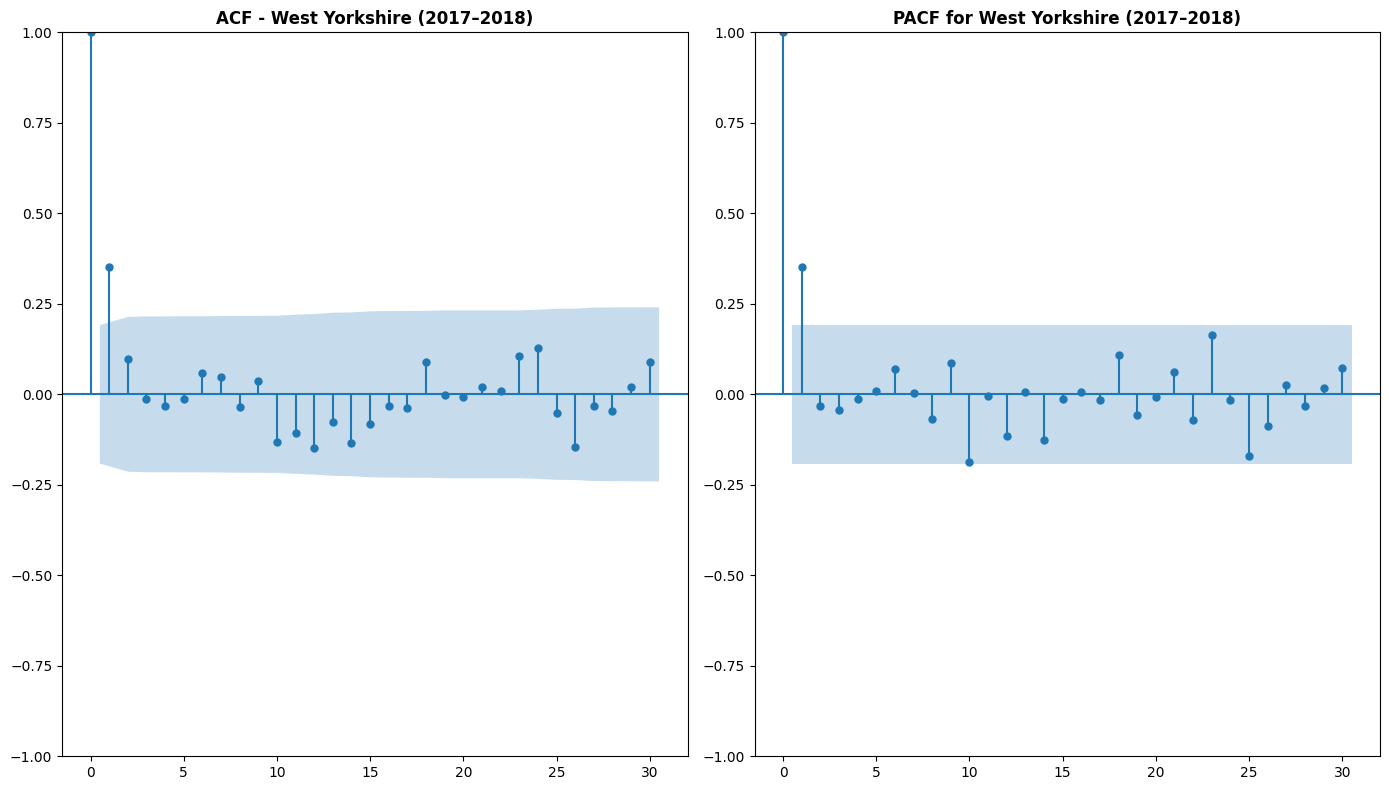

In [40]:
# ADF Stationarity Test for each police force

print('ADF Stationarity Tests:\n')

for code, name in TASK6_FORCES.items():

    # Get weekly training data (2017–2018)
    train = build_weekly_series(acc_3yr, code).loc['2017':'2018']

    # Run ADF test
    adf_stat, p_val = adfuller(train)[:2]

    # Interpret result
    result = 'Stationary' if p_val < 0.05 else 'Non-stationary'

    print(f'{name}: ADF={adf_stat:.4f}, p={p_val:.6f} implies {result}')

    # If not stationary then apply first differencing
    if p_val >= 0.05:
        diff = train.diff().dropna()
        stat2, p2 = adfuller(diff)[:2]

        status = 'Stationary' if p2 < 0.05 else 'Still non-stationary'
        print(f'After differencing: ADF={stat2:.4f}, p={p2:.6f} implies {status}')
        
    print()  # blank line between forces


# ACF & PACF plots (West Yorkshire example)
wy_train = build_weekly_series(acc_3yr, 13).loc['2017':'2018']

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# ACF shows correlation with past values
plot_acf(wy_train, lags=30, ax=axes[0])
axes[0].set_title('ACF - West Yorkshire (2017–2018)', fontweight='bold')

# PACF shows direct influence of lagged values
plot_pacf(wy_train, lags=30, ax=axes[1], method='ywm')
axes[1].set_title('PACF for West Yorkshire (2017–2018)', fontweight='bold')

# Adjust layout and display plot
plt.tight_layout()
plt.show()

###
**Model 1: SARIMA**

In [41]:
# SARIMA model (select best order using AIC)

# Candidate parameter combinations (p,d,q,P,D,Q)
orders = [
    (1,0,0,1,1,0), (0,0,1,1,1,0), (1,0,1,1,1,0),
    (1,0,0,1,0,0), (0,0,1,1,0,1), (1,0,1,1,0,0),
    (1,0,0,0,0,1), (0,0,1,0,0,1), (1,0,1,0,0,1),
    (1,1,0,1,0,0), (1,1,1,1,1,0), (0,1,1,1,1,0)
]

sarima_results = {}

for code, name in TASK6_FORCES.items():

    # Split data
    weekly = build_weekly_series(acc_3yr, code)
    train  = weekly.loc['2017':'2018']
    test   = weekly.loc['2019']

    train_sub = train[:-12] # training data
    val = train[-12:] # validation (last 12 weeks)

    best_mae  = float('inf')
    best_order = None

    # Try each candidate order
    for p, d, q, P, D, Q in orders:
        try:
            model = SARIMAX(
                train_sub,
                order=(p,d,q),
                seasonal_order=(P,D,Q,52),
                enforce_stationarity=False,
                enforce_invertibility=False
            ).fit(disp=False)

            # Validate
            pred = model.forecast(len(val)).clip(lower=0)
            mae  = mean_absolute_error(val, pred)

            if mae < best_mae:
                best_mae  = mae
                best_order = (p,d,q,P,D,Q)

        except:
            continue

    # Refit best model on full training data
    p,d,q,P,D,Q = best_order
    final_model = SARIMAX(
        train,
        order=(p,d,q),
        seasonal_order=(P,D,Q,52),
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    # Forecast 2019
    forecast = final_model.forecast(len(test)).clip(lower=0)
    forecast.index = test.index

    # Metrics
    mae  = mean_absolute_error(test, forecast)
    mse = mean_squared_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))
    mape = np.mean(np.abs((test - forecast) / test.replace(0, np.nan))) * 100

    # Store results
    sarima_results[code] = {
        'name': name,
        'order': best_order,
        'forecast': forecast,
        'mae': mae,
        'mse': mse, 
        'rmse': rmse,
        'mape': mape
    }

    # Display output
    print(f'{name}: best order={best_order} (val MAE={best_mae:.2f})')
    print(f'MAE={mae:.2f}, RMSE={rmse:.2f}, MAPE={mape:.1f}%\n')

Metropolitan Police: best order=(0, 0, 1, 1, 0, 1) (val MAE=16.87)
MAE=40.39, RMSE=58.76, MAPE=11.7%

West Midlands: best order=(1, 0, 1, 1, 1, 0) (val MAE=12.63)
MAE=17.25, RMSE=21.19, MAPE=18.0%

West Yorkshire: best order=(1, 1, 1, 1, 1, 0) (val MAE=10.57)
MAE=11.78, RMSE=14.48, MAPE=18.1%



###
**Model 2: Holt-Winters**

In [42]:
# Holt-Winters (Grid Search Tuning)

hw_results = {}  # Store results for each police force

for code, name in TASK6_FORCES.items():

    # Prepare data
    weekly = build_weekly_series(acc_3yr, code)
    train  = weekly.loc['2017':'2018']
    test   = weekly.loc['2019']

    best_sse = np.inf # keeps track of lowest training error
    best_model = None # stores the model with best performance
    best_params = None # stores corresponding (alpha, beta, gamma)

    # Grid search over smoothing parameters
    for alpha in [0.1, 0.2, 0.3, 0.5]: # level smoothing
        for beta in [0.01, 0.05, 0.1, 0.2]: # trend smoothing
            for gamma in [0.05, 0.1, 0.2, 0.3]: # seasonal smoothing
                try:
                    model = ExponentialSmoothing(
                        train,
                        trend='add',
                        seasonal='add',
                        seasonal_periods=52
                    ).fit(
                        smoothing_level=alpha,
                        smoothing_trend=beta,
                        smoothing_seasonal=gamma
                    )

                    # Evaluate using training SSE (sum of squared errors)
                    sse = np.sum(model.resid ** 2)

                    if sse < best_sse:
                        best_sse = sse
                        best_model = model
                        best_params = (alpha, beta, gamma)

                except:
                    continue  # skip invalid parameter combinations

    # Forecast and evaluate
    forecast = best_model.forecast(len(test))
    forecast.index = test.index
    forecast = np.clip(forecast, 0, None)

    mae  = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))
    mse  = mean_squared_error(test, forecast)
    mape = np.mean(np.abs((test - forecast) / test.replace(0, np.nan))) * 100

    # Store results
    hw_results[code] = {
        'name': name,
        'train': train,
        'test': test,
        'forecast': forecast,
        'model': best_model,
        'params': best_params,
        'mae': mae,
        'rmse': rmse,
        'mse': mse,
        'mape': mape
    }

    # Output summary
    alpha, beta, gamma = best_params
    print(f'{name}:')
    print(f'Best params: alpha={alpha}, beta={beta}, gamma={gamma}')
    print(f'MAE={mae:.2f}, RMSE={rmse:.2f}, MAPE={mape:.1f}%\n')

Metropolitan Police:
Best params: alpha=0.1, beta=0.01, gamma=0.05
MAE=41.95, RMSE=55.33, MAPE=12.4%

West Midlands:
Best params: alpha=0.1, beta=0.01, gamma=0.05
MAE=13.73, RMSE=17.20, MAPE=14.7%

West Yorkshire:
Best params: alpha=0.3, beta=0.01, gamma=0.05
MAE=10.42, RMSE=12.57, MAPE=17.8%



###
**Model 3: XGBoost**

In [43]:
# XGBoost (Feature Engineering and Hyperparameter Tuning)

"""
This approach converts the time series forecasting problem into a supervised
regression task by creating lag-based and time-based features.
"""

"""
Feature set used by the model:
 - Lag features: capture short-term and seasonal dependencies
 - Time features: help model calendar-based patterns
 - Trend: captures long-term direction in the data
"""

FEAT_COLS = [
    'lag_1', 'lag_2', 'lag_3', 'lag_52',   # previous values (short + yearly lag)
    'week_of_year', 'month', 'year',       # seasonal signals
    'trend'                                # long-term progression
]


def make_xgb_features(series):
    df = series.reset_index()
    df.columns = ['date', 'accidents']

    # Create lag features
    for lag in [1, 2, 3, 52]:
        df[f'lag_{lag}'] = df['accidents'].shift(lag)

    # Extract calendar-based features
    df['week_of_year'] = df['date'].dt.isocalendar().week.astype(int)
    df['month'] = df['date'].dt.month
    df['year']  = df['date'].dt.year

    # Add trend feature
    df['trend'] = np.arange(len(df))

    return df.dropna() # Drop rows with NaN values caused by lagging


# Model training and evaluation
xgb_results = {}

for code, name in TASK6_FORCES.items():

    # Prepare dataset
    weekly = build_weekly_series(acc_3yr, code)
    df = make_xgb_features(weekly)

    # Split data
    train = df[df['date'] < '2019-01-01'] # training set: before 2019
    test  = df[df['date'] >= '2019-01-01'] # testing set: 2019

    X_train, y_train = train[FEAT_COLS], train['accidents']
    X_test, y_test = test[FEAT_COLS],  test['accidents']


    # Baseline model (no hyperparameter tuning)
    base_model = XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=RANDOM_STATE
    )

    base_model.fit(X_train, y_train)

    # Ensure predictions are non-negative (counts shouldn't be negative)
    pred_base = np.clip(base_model.predict(X_test), 0, None)

    mae_base  = mean_absolute_error(y_test, pred_base)

    print(f'{name} - Baseline MAE: {mae_base:.2f}')

   
    # Hyperparameter tuning (Grid Search - Uses 3-fold cross-validation to improve generalisation)
    """
    Searches over combinations of key parameters:
     - n_estimators: number of boosting rounds
     - learning_rate: controls learning speed
     - max_depth: tree complexity
    """
    param_grid = {
        'n_estimators':  [100, 200],
        'learning_rate': [0.05, 0.1],
        'max_depth':     [3, 5]
    }

    grid = GridSearchCV(
        XGBRegressor(random_state=RANDOM_STATE),
        param_grid,
        scoring='neg_mean_squared_error', # minimise MSE
        cv=3,
        n_jobs=-1 # parallel processing
    )
    grid.fit(X_train, y_train)

    
    # Evaluate tuned model
    pred = np.clip(grid.best_estimator_.predict(X_test), 0, None)

    # Performance metrics
    mae  = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mse  = mean_squared_error(y_test, pred)
    mape = np.mean(np.abs((y_test - pred) / y_test.replace(0, np.nan))) * 100

    print(f'{name} - Best params: {grid.best_params_}')
    print(f'{name} - MAE={mae:.2f}, RMSE={rmse:.2f}, MAPE={mape:.1f}%\n')

    # Store results
    xgb_results[code] = {
        'name': name,
        'y_test': y_test,
        'dates': test['date'],
        'preds': pred,
        'best_params': grid.best_params_,
        'mae': mae,
        'rmse': rmse,
        'mse': mse,
        'mape': mape,
        'mae_baseline': mae_base
    }

Metropolitan Police - Baseline MAE: 56.79
Metropolitan Police - Best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
Metropolitan Police - MAE=43.15, RMSE=60.29, MAPE=13.0%

West Midlands - Baseline MAE: 16.02
West Midlands - Best params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100}
West Midlands - MAE=16.17, RMSE=19.24, MAPE=18.3%

West Yorkshire - Baseline MAE: 25.36
West Yorkshire - Best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
West Yorkshire - MAE=17.36, RMSE=20.85, MAPE=27.8%



###
**Model Comparisons**

In [44]:
# Model Comparison Table

comparison_rows = []

# Loop through each policing area and collect model results
for code, name in TASK6_FORCES.items():
    hw = hw_results[code] # Holt-Winters results
    s  = sarima_results[code] # SARIMA results
    x  = xgb_results[code] # XGBoost results

    comparison_rows.append({
        'Policing Area': name,

        # SARIMA metrics
        'SARIMA MAE': round(s['mae'], 2),
        'SARIMA RMSE': round(s['rmse'], 2),
        'SARIMA MSE': round(s['mse'], 2),
        'SARIMA MAPE%': round(s['mape'], 1),
        
        # Holt-Winters metrics
        'HW MAE': round(hw['mae'], 2),
        'HW RMSE': round(hw['rmse'], 2),
        'HW MSE': round(hw['mse'], 2),
        'HW MAPE%': round(hw['mape'], 1),

        # XGBoost metrics
        'XGB MAE': round(x['mae'], 2),
        'XGB RMSE': round(x['rmse'], 2),
        'XGB MSE': round(x['mse'], 2),
        'XGB MAPE%': round(x['mape'], 1),
    })

# Create comparison table
comp_df = pd.DataFrame(comparison_rows)

# Display results
print('\nModel Performance Comparison (2019 Forecast)')
print(comp_df.to_string(index=False))

# Identify best model per policing area (based on MAE)
print('\nBest model by MAE:')

# Iterates through each row of the comparison DataFrame, which contains MAE values for all three models.
for _, row in comp_df.iterrows():
    # Store MAE values for each model in a dictionary
    maes = {
        'Holt-Winters': row['HW MAE'],
        'SARIMA': row['SARIMA MAE'],
        'XGBoost': row['XGB MAE']
    }

    # The model with the lowest MAE is considered the most accurate
    best_model = min(maes, key=maes.get)

    # Display output
    print(f'{row["Policing Area"]}: {best_model} (MAE={maes[best_model]:.2f})')


Model Performance Comparison (2019 Forecast)
      Policing Area  SARIMA MAE  SARIMA RMSE  SARIMA MSE  SARIMA MAPE%  HW MAE  HW RMSE  HW MSE  HW MAPE%  XGB MAE  XGB RMSE  XGB MSE  XGB MAPE%
Metropolitan Police       40.39        58.76     3453.16          11.7   41.95    55.33 3061.29      12.4    43.15     60.29  3634.77       13.0
      West Midlands       17.25        21.19      448.92          18.0   13.73    17.20  295.78      14.7    16.17     19.24   370.30       18.3
     West Yorkshire       11.78        14.48      209.64          18.1   10.42    12.57  158.08      17.8    17.36     20.85   434.60       27.8

Best model by MAE:
Metropolitan Police: SARIMA (MAE=40.39)
West Midlands: Holt-Winters (MAE=13.73)
West Yorkshire: Holt-Winters (MAE=10.42)


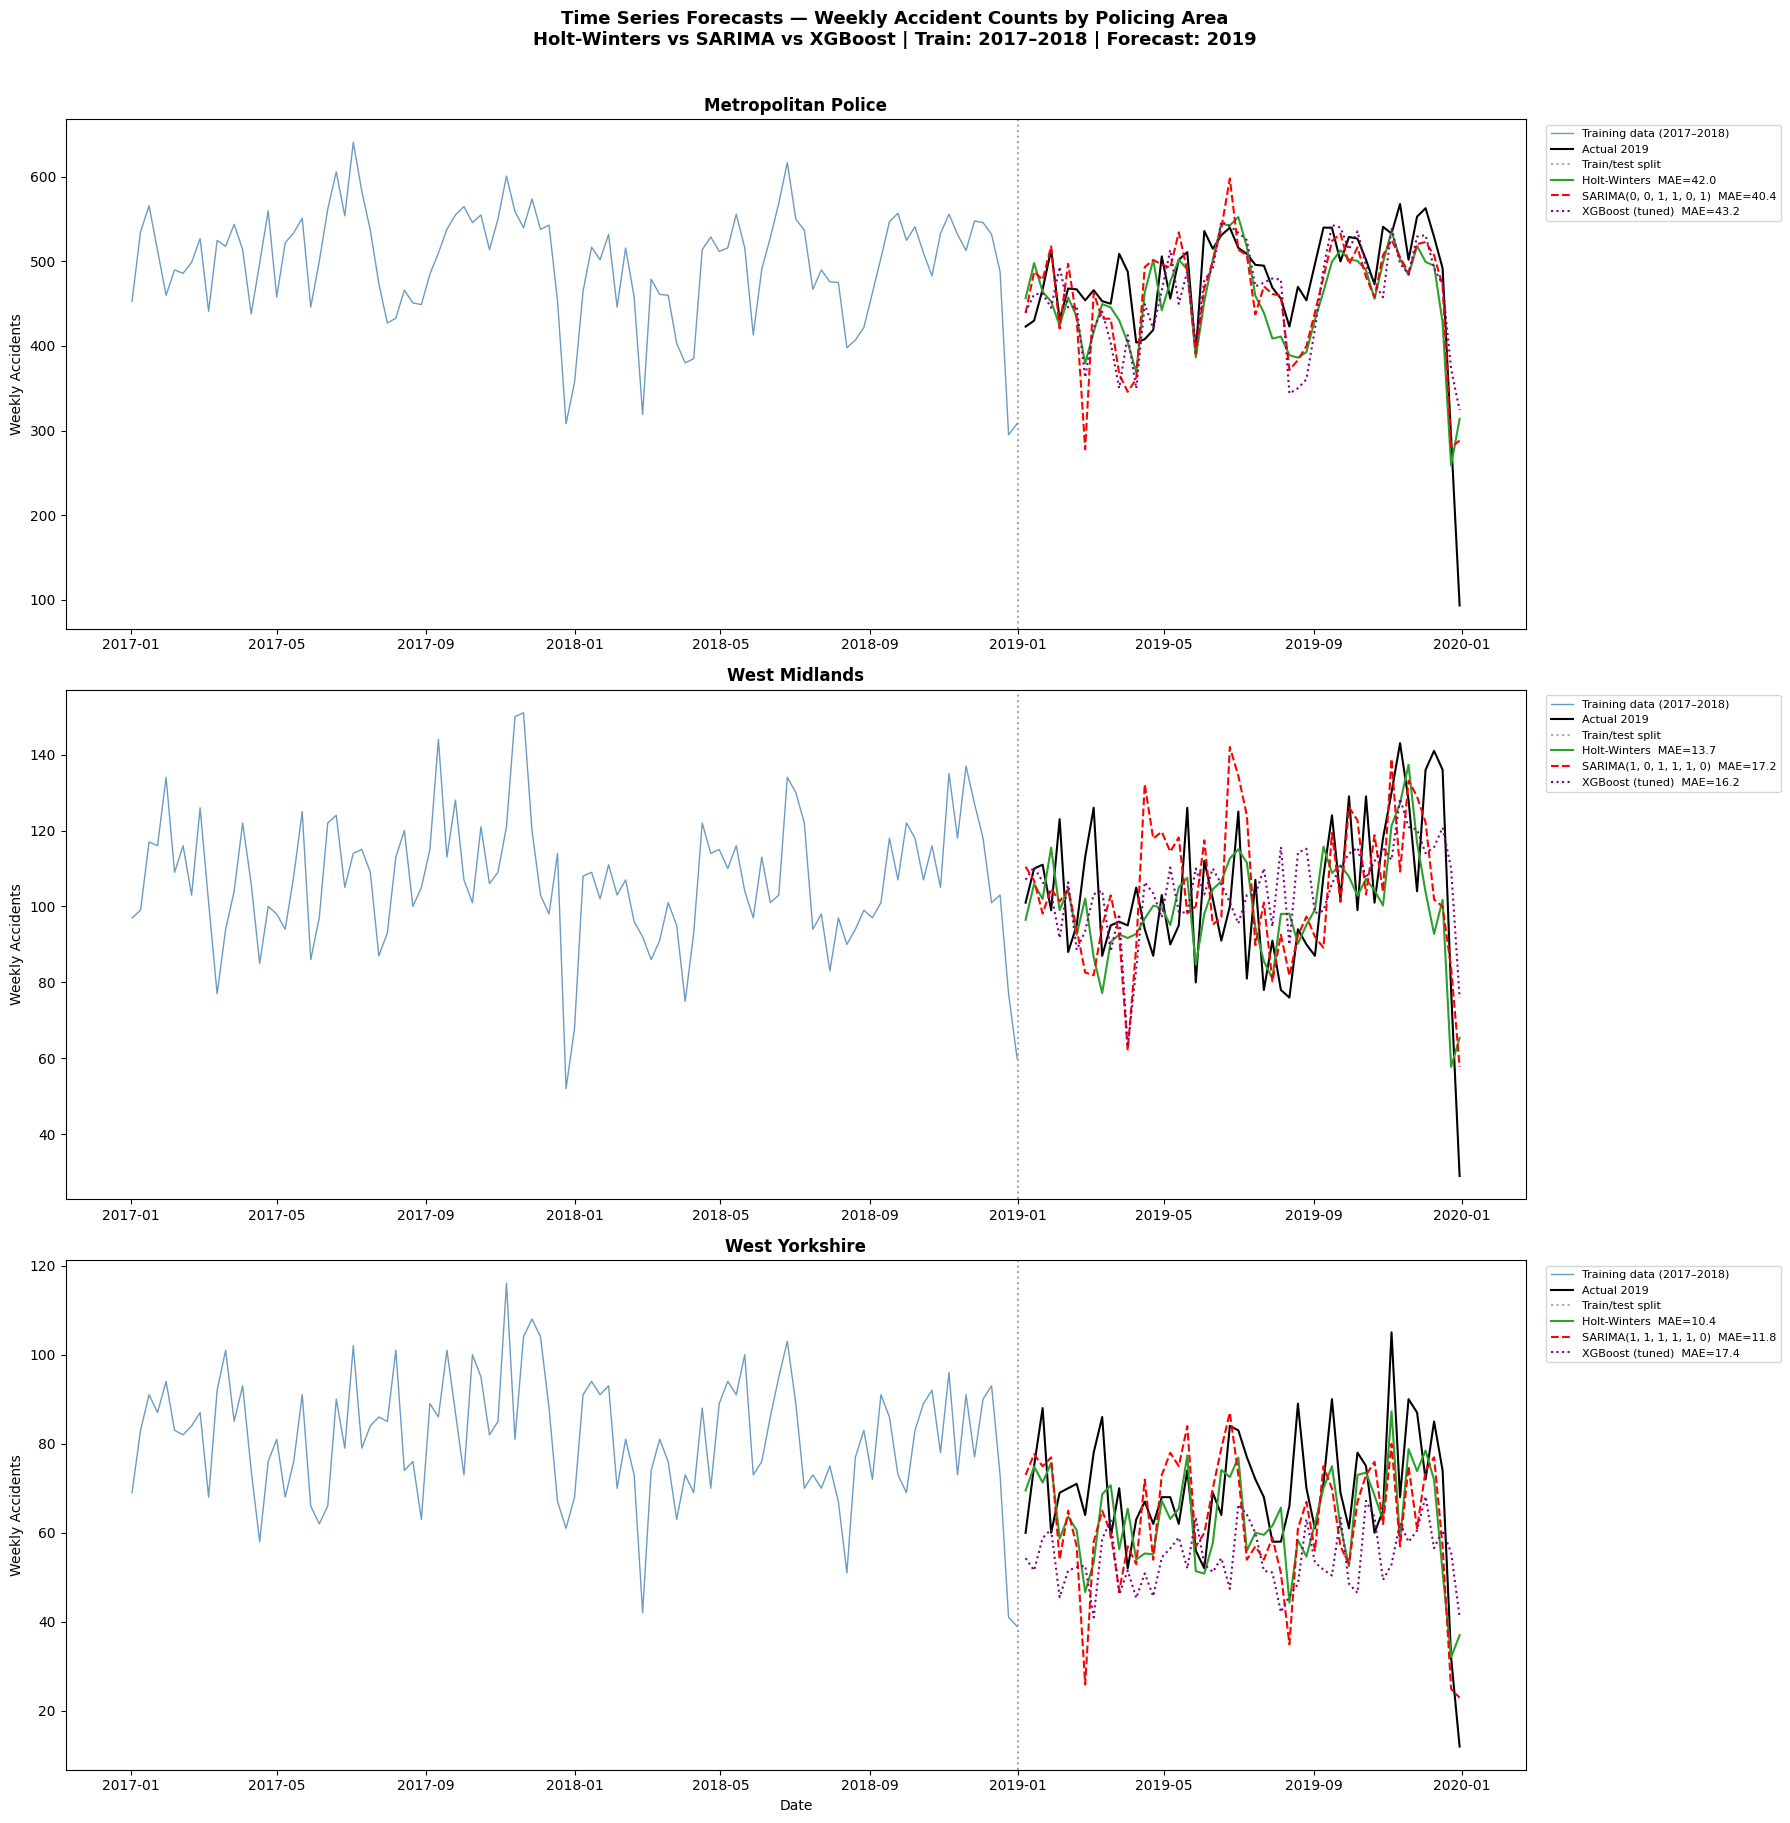

In [45]:
# Combined Forecast Plots (Comparing All Models)

# Create figure with one subplot per policing area
fig, axes = plt.subplots(3, 1, figsize=(18, 18))

for ax, (code, name) in zip(axes, TASK6_FORCES.items()):

    # Retrieve stored results for each model
    s  = sarima_results[code] # SARIMA results
    hw = hw_results[code] # Holt-Winters results
    x  = xgb_results[code] # XGBoost results

  
    # Viz 1: Training data (2017–2018) - Shows the historical data used to fit the models
    ax.plot(
        hw['train'].index, hw['train'].values,
        color='steelblue', linewidth=1, alpha=0.8,
        label='Training data (2017–2018)'
    )

    # Viz 2: Actual observed values (2019) - Ground truth used to evaluate forecast accuracy
    ax.plot(
        hw['test'].index, hw['test'].values,
        color='black', linewidth=1.5,
        label='Actual 2019'
    )

    # Visual marker: Train/Test split - indicates where forecasting begins
    ax.axvline(
        pd.Timestamp('2019-01-01'),
        color='grey', linestyle=':',
        linewidth=1.5, alpha=0.7,
        label='Train/test split'
    )

    # Viz 3: Holt-Winters forecast
    ax.plot(
        hw['forecast'].index, hw['forecast'].values,
        color='#2CA02C', linestyle='-', linewidth=1.5,
        label=f'Holt-Winters  MAE={hw["mae"]:.1f}'
    )

    # Viz 4: SARIMA forecast
    ax.plot(
        s['forecast'].index, s['forecast'].values,
        color='red', linestyle='--', linewidth=1.5,
        label=f'SARIMA{s["order"]}  MAE={s["mae"]:.1f}'
    )
    
    # Viz 5: XGBoost forecast
    ax.plot(
        x['dates'].values, x['preds'],
        color='purple', linestyle=':', linewidth=1.5,
        label=f'XGBoost (tuned)  MAE={x["mae"]:.1f}'
    )

    # Format each subplot
    ax.set_title(f'{name}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Weekly Accidents')

    # Format y-axis with comma separators for readability
    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(lambda v, _: f'{int(v):,}')
    )

    ax.legend(fontsize=8, 
              loc='upper left', # anchor point of legend box
              bbox_to_anchor=(1.01, 1)) # position legend just outside the axes


# Global formatting
axes[-1].set_xlabel('Date')

# Overall figure title
plt.suptitle(
    'Time Series Forecasts — Weekly Accident Counts by Policing Area\n'
    'Holt-Winters vs SARIMA vs XGBoost | Train: 2017–2018 | Forecast: 2019',
    fontsize=13, fontweight='bold', y=1.01
)

# Adjust layout to prevent overlapping elements
plt.tight_layout()

# Display plot
plt.show()

##
## Task 7: Daily Accident Forecast - Top 30 West Yorkshire LSOAs (July 2018)

The top 30 LSOAs by Q1 2018 (January - March) accident count are identified and aggregated into a single daily series covering January - June 2018. Two models are fitted on this training window and used to forecast daily accident counts for July 2018: SARIMA (primary) and Holt-Winters (secondary).

**Identify Top 30 West Yorkshire LSOAs by Q1 2018 Accident Count**

In [46]:
# Filter dataset to West Yorkshire accidents (2018 only)
wy_2018 = acc2018_raw[acc2018_raw['police_force'] == WY_FORCE].copy()

# Convert 'date' column to datetime format
wy_2018['date'] = pd.to_datetime(wy_2018['date'], dayfirst=True, errors='coerce')

# Remove rows with missing or invalid dates and missing LSOA codes
wy_2018 = wy_2018.dropna(subset=['date', 'lsoa_of_accident_location'])

# Select Q1 data (January–March)
q1_wy = wy_2018[wy_2018['date'].dt.month.isin([1, 2, 3])]

# Identify top 30 LSOAs by accident count
# Group by LSOA code, count accidents, select top 30
top30 = (
    q1_wy.groupby('lsoa_of_accident_location')
         .size()
         .nlargest(30)
         .reset_index(name='q1_count')
)

# Add LSOA names via lookup table
top30 = top30.merge(
    lsoa_df,
    left_on='lsoa_of_accident_location',
    right_on='lsoa01cd',
    how='left'
)

# For unmatched LSOAs use the raw code as the display label and flag as boundary mismatch
top30['lsoa01cd'] = top30['lsoa01cd'].fillna(
    top30['lsoa_of_accident_location']
)
top30['lsoa01nm'] = top30['lsoa01nm'].fillna('Name not found')

# Store top 30 LSOA codes for filtering
TOP30_CODES = top30['lsoa_of_accident_location'].tolist()

# Display results
n_unmatched = (top30['lsoa01nm'] == 'Name not found').sum()
print(f'Top 30 West Yorkshire LSOAs (Q1 2018):')
print()
print(top30[['lsoa01cd', 'lsoa01nm', 'q1_count']].to_string(index=False))

Top 30 West Yorkshire LSOAs (Q1 2018):

 lsoa01cd        lsoa01nm  q1_count
E01011499      Leeds 105C        11
E01011107   Kirklees 029D         8
E01033010  Name not found         8
E01033693  Name not found         8
E01010833   Bradford 041C         7
E01011236   Kirklees 034B         7
E01011369      Leeds 090E         7
E01011569      Leeds 004A         6
E01011935  Wakefield 038A         6
E01033005  Name not found         6
E01010979 Calderdale 017D         5
E01011130   Kirklees 017B         5
E01011205   Kirklees 036D         5
E01011297      Leeds 030B         5
E01011363      Leeds 071E         5
E01011428      Leeds 048C         5
E01011468      Leeds 084C         5
E01011523      Leeds 096C         5
E01011677      Leeds 064D         5
E01033031  Name not found         5
E01010613   Bradford 045B         4
E01010639   Bradford 004B         4
E01010834   Bradford 044A         4
E01010879 Calderdale 015B         4
E01010934 Calderdale 008A         4
E01010949 Calderdale 019

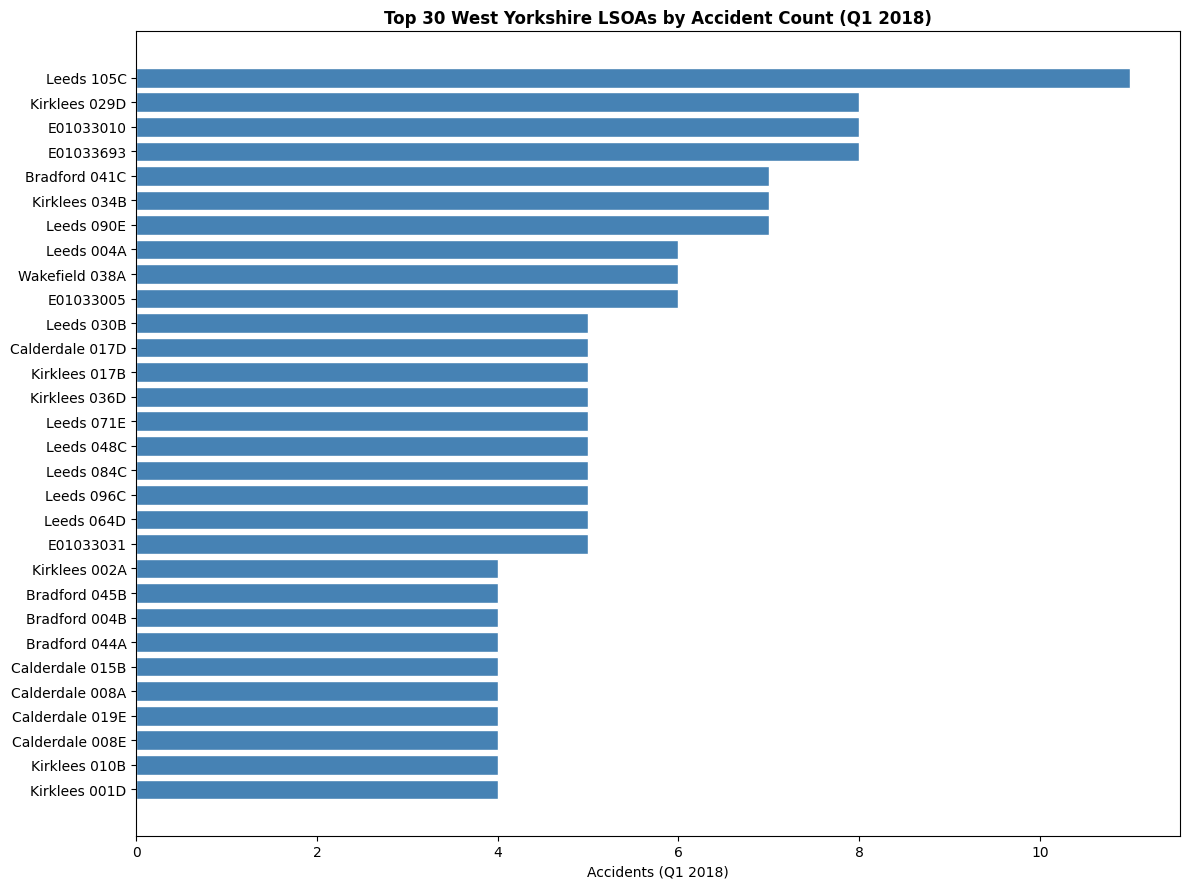

In [47]:
# Visualise Top 30 LSOAs (Q1 2018)

# Sort data in ascending order ensures the highest values appear at the top
top30_sorted = top30.sort_values('q1_count')

# Create labels for the y-axis
labels = top30_sorted.apply(
    lambda r: r['lsoa01nm']
    if r['lsoa01nm'] != 'Name not found'
    else r['lsoa01cd'],
    axis=1
)

# Create horizontal bar chart
plt.figure(figsize=(12, 9))

plt.barh(labels,
         top30_sorted['q1_count'],
         color='steelblue',
         edgecolor='white')


# Add axis labels and title
plt.xlabel('Accidents (Q1 2018)')

plt.title('Top 30 West Yorkshire LSOAs by Accident Count (Q1 2018)', fontsize=12, fontweight='bold')

# Adjust layout
plt.tight_layout()

# Display plot
plt.show()

###
**Build Daily Time Series (Jan–Jun 2018)**

Training period: 2018-01-01 to 2018-06-29
Days: 180
Mean/day: 1.54
Std deviation: 1.24
July total: 34
July mean/day: 1.10


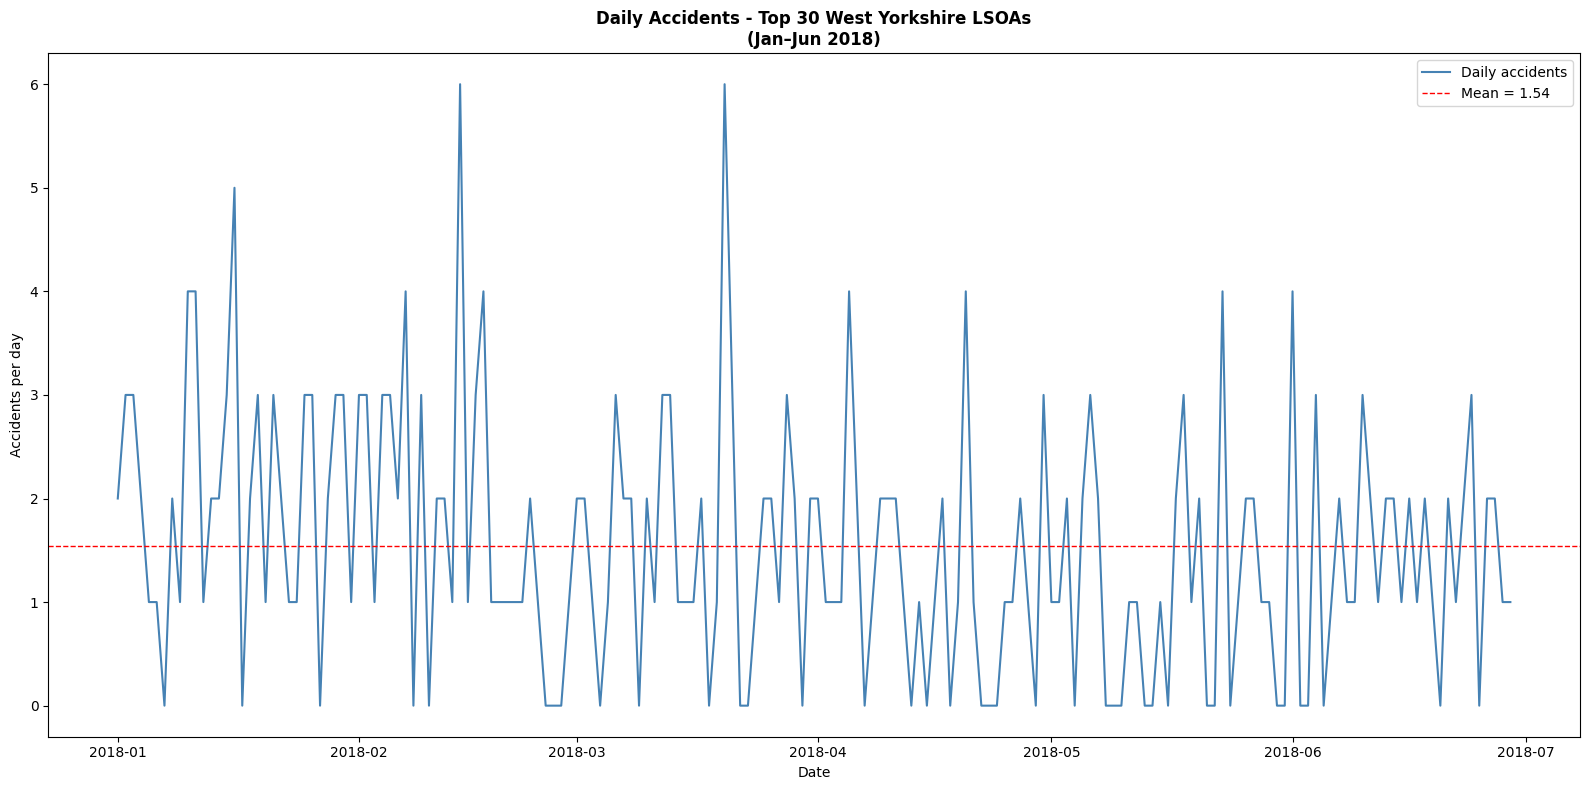

In [49]:
# Filter to top 30 LSOAs and months Jan–Jun (training data)
train_src = wy_2018[
    wy_2018['lsoa_of_accident_location'].isin(TOP30_CODES) &
    wy_2018['date'].dt.month.isin([1, 2, 3, 4, 5, 6])
]

# Aggregate to daily accident counts (fill missing days with 0)
daily_train = (
    train_src.groupby('date')
             .size()
             .asfreq('D', fill_value=0)
)

# Prepare July 2018 data for evaluation
actual_src = wy_2018[
    wy_2018['lsoa_of_accident_location'].isin(TOP30_CODES) &
    (wy_2018['date'].dt.month == 7)
]

# Ensure full July date range (1–31) with missing days filled as 0
july_dates  = pd.date_range('2018-07-01', periods=31, freq='D')
actual_july = (actual_src.groupby('date').size().reindex(july_dates, fill_value=0))


# Summary statistics
print(f'Training period: {daily_train.index[0].date()} to {daily_train.index[-1].date()}')
print(f'Days: {len(daily_train)}')
print(f'Mean/day: {daily_train.mean():.2f}')
print(f'Std deviation: {daily_train.std():.2f}')
print(f'July total: {actual_july.sum()}')
print(f'July mean/day: {actual_july.mean():.2f}')


# Plot daily training series
plt.figure(figsize=(16, 8))

plt.plot(daily_train.index,
         daily_train.values,
         color='steelblue',
         linewidth=1.5,
         label='Daily accidents')

# Add mean reference line
plt.axhline(daily_train.mean(), 
            color='red',
            linestyle='--',
            linewidth=1,
            label=f'Mean = {daily_train.mean():.2f}')

plt.title(
    'Daily Accidents - Top 30 West Yorkshire LSOAs\n(Jan–Jun 2018)',
    fontsize=12,
    fontweight='bold'
)

# Add labels
plt.xlabel('Date')
plt.ylabel('Accidents per day')
plt.legend()

# Adjust layout and display plot
plt.tight_layout()
plt.show()

###
**ADF Stationarity Test (Daily Series)**

In [50]:
# Perform ADF test on training data

adf_stat, adf_p = adfuller(daily_train)[:2]

# Determine stationarity based on p-value
is_stationary = adf_p < 0.05

# Display ADF test results
print('ADF Test - Daily Accidents (Jan–Jun 2018)')
print(f'ADF Statistic: {adf_stat:.4f}')
print(f'p-value: {adf_p:.6f}')
print(f'Result: {"Stationary" if is_stationary else "Non-stationary"}')

"""
 Suggest next modelling step based on result
 - If stationary -> no differencing needed (d = 0)
 - If not -> apply differencing (d = 1)
"""
print(f'Next step: {"No differencing needed (d=0)" if is_stationary else "Apply differencing (d=1)"}')


# Apply first-order differencing if the series is non-stationary
# Differencing removes trends and stabilises the mean over time
if not is_stationary:

    # First-order differencing (y_t - y_{t-1})
    diff1 = daily_train.diff().dropna()

    # Re-run ADF test on differenced series
    adf2_stat, adf2_p = adfuller(diff1)[:2]
    is_stationary_2 = adf2_p < 0.05

    # Display results after differencing
    print('\nAfter first differencing:')
    print(f'ADF Statistic: {adf2_stat:.4f}')
    print(f'p-value: {adf2_p:.6f}')
    print(f'Result: {"Stationary" if is_stationary_2 else "Still non-stationary"}')

ADF Test - Daily Accidents (Jan–Jun 2018)
ADF Statistic: -3.4086
p-value: 0.010669
Result: Stationary
Next step: No differencing needed (d=0)


###
**SARIMA Model (Daily Data)**

In [51]:
"""
 Forecast daily accident counts using a SARIMA model that captures:
 - Short-term dynamics (ARIMA components)
 - Weekly seasonality (m = 7, based on day-of-week patterns)


 Model selection is performed using a validation approach:
 - Last 7 days of training data are used to choose the best order
"""

# Candidate SARIMA orders (p, d, q, P, D, Q)
DAILY_ORDERS = [
    (1,0,0,1,1,0), (0,0,1,1,1,0), (1,0,1,1,1,0),
    (1,0,0,0,1,1), (0,0,1,0,1,1), (1,1,0,1,1,0),
    (0,1,1,1,1,0), (1,1,1,1,1,0), (1,0,0,1,0,0),
    (0,0,1,1,0,1)
]

# Create validation split
# Training subset (all data except last 7 days)
# Validation set (last 7 days)
train_sub = daily_train.iloc[:-7]
val = daily_train.iloc[-7:]

best_val_mae = np.inf # Track lowest validation error
best_order = None # Store best SARIMA configuration

"""
 Grid search over candidate SARIMA orders
 Each configuration is:
 - Fitted on training subset
 - Evaluated on validation data
"""
for p, d, q, P, D, Q in DAILY_ORDERS:
    try:
        model = SARIMAX(
            train_sub,
            order=(p, d, q), # non-seasonal terms
            seasonal_order=(P, D, Q, 7), # seasonal terms (weekly cycle)
            enforce_stationarity=False, # relax constraints for flexibility
            enforce_invertibility=False
        ).fit(disp=False)

        # Forecast validation period (7 days ahead)
        fc_val = np.clip(model.forecast(7), 0, None)

        # Evaluate using MAE
        val_mae = mean_absolute_error(val, fc_val)

        # Update best model if performance improves
        if val_mae < best_val_mae:
            best_val_mae = val_mae
            best_order   = (p, d, q, P, D, Q)

    except Exception:
        # Skip configurations that fail to converge
        continue


# Display selected best model configuration
print(f'Best order: {best_order} (MAE={best_val_mae:.3f})')


# Fit final SARIMA model on full training data
# Uses best parameters found during validation
p, d, q, P, D, Q = best_order

sarima_daily = SARIMAX(
    daily_train,
    order=(p, d, q),
    seasonal_order=(P, D, Q, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)


# Forecast future period (July 2018 — 31 days)
# Predictions are clipped to ensure no negative accident counts
sarima_fc = np.clip(sarima_daily.forecast(31), 0, None)
sarima_fc.index = july_dates  # align forecast with actual dates


# Evaluate forecast performance
mae_s  = mean_absolute_error(actual_july, sarima_fc)
rmse_s = np.sqrt(mean_squared_error(actual_july, sarima_fc))
mse_s  = mean_squared_error(actual_july, sarima_fc)

# Avoid division by zero in MAPE
mape_s = np.mean(np.abs((actual_july - sarima_fc) / actual_july.replace(0, np.nan))) * 100


# Output results
print('\nSARIMA Forecast (July 2018)')
print(f'MAE: {mae_s:.3f}')
print(f'RMSE: {rmse_s:.3f}')
print(f'MSE: {mse_s:.3f}')
print(f'MAPE: {mape_s:.1f}%')

# Compare total predicted vs actual accidents
print(f'Total: {sarima_fc.sum():.1f} (forecast) vs {actual_july.sum()} (actual)')

Best order: (1, 0, 1, 1, 1, 0) (MAE=0.928)

SARIMA Forecast (July 2018)
MAE: 1.177
RMSE: 1.400
MSE: 1.961
MAPE: 53.8%
Total: 45.9 (forecast) vs 34 (actual)


###
**Holt-Winters Model (Daily Data)**

In [52]:
# Forecast daily accident counts using Holt-Winters exponential smoothing.

# Parameter selection is performed via manual grid search, choosing the combination that minimises training SSE (Sum of Squared Errors).


# Initialise tracking variables
best_sse = np.inf # lowest training error found
best_model = None # best fitted model
best_params = None # corresponding (alpha, beta, gamma)


# Grid search over smoothing parameters
"""
 Parameters:
 - alpha: level smoothing (how quickly the model adapts to new values)
 - beta : trend smoothing (sensitivity to trend changes)
 - gamma: seasonal smoothing (sensitivity to seasonal variation)
"""
# Lower values: smoother estimates
# Higher values: more responsive to recent changes
for alpha in [0.1, 0.2, 0.3, 0.5]:
    for beta in [0.01, 0.05, 0.1]:
        for gamma in [0.05, 0.1, 0.2]:
            try:
                # Fit Holt-Winters model with fixed parameters
                model = ExponentialSmoothing(
                    daily_train,
                    trend='add', # linear trend component
                    seasonal='add', # additive seasonality
                    seasonal_periods=7 # weekly cycle (daily data)
                ).fit(
                    smoothing_level=alpha,
                    smoothing_trend=beta,
                    smoothing_seasonal=gamma,
                    optimized=False
                )

                # Evaluate model using training SSE
                sse = np.sum(model.resid ** 2)

                # Update best model if current combination performs better
                if sse < best_sse:
                    best_sse    = sse
                    best_model  = model
                    best_params = (alpha, beta, gamma)

            except Exception:
                # Some parameter combinations may fail to converge
                continue


# Display best parameter combination
alpha, beta, gamma = best_params
print(f'Best params: alpha={alpha}, beta={beta}, gamma={gamma}')
print(f'Training SSE: {best_sse:.2f}')


# Forecast future period (July 2018 — 31 days)
# Generate predictions using the best model
# Values are clipped to ensure no negative accident counts
hw_fc = np.clip(best_model.forecast(31), 0, None)
hw_fc.index = july_dates # align forecast with actual dates


# Evaluate forecast performance
mae_h  = mean_absolute_error(actual_july, hw_fc)
rmse_h = np.sqrt(mean_squared_error(actual_july, hw_fc))
mse_h  = mean_squared_error(actual_july, hw_fc)
mape_h = np.mean(np.abs((actual_july - hw_fc) / actual_july.replace(0, np.nan))) * 100


# Output results
print('\nHolt-Winters Forecast (July 2018)')
print(f'MAE: {mae_h:.3f}')
print(f'RMSE: {rmse_h:.3f}')
print(f'MSE: {mse_h:.3f}')
print(f'MAPE: {mape_h:.1f}%')

# Compare total predicted vs actual accidents
print(f'Total: {hw_fc.sum():.1f} (forecast) vs {actual_july.sum()} (actual)')

Best params: alpha=0.1, beta=0.1, gamma=0.1
Training SSE: 318.12

Holt-Winters Forecast (July 2018)
MAE: 1.023
RMSE: 1.197
MSE: 1.433
MAPE: 45.6%
Total: 46.7 (forecast) vs 34 (actual)


###
**Plot Forecasts vs Actual (July 2018) and Model Comparison**

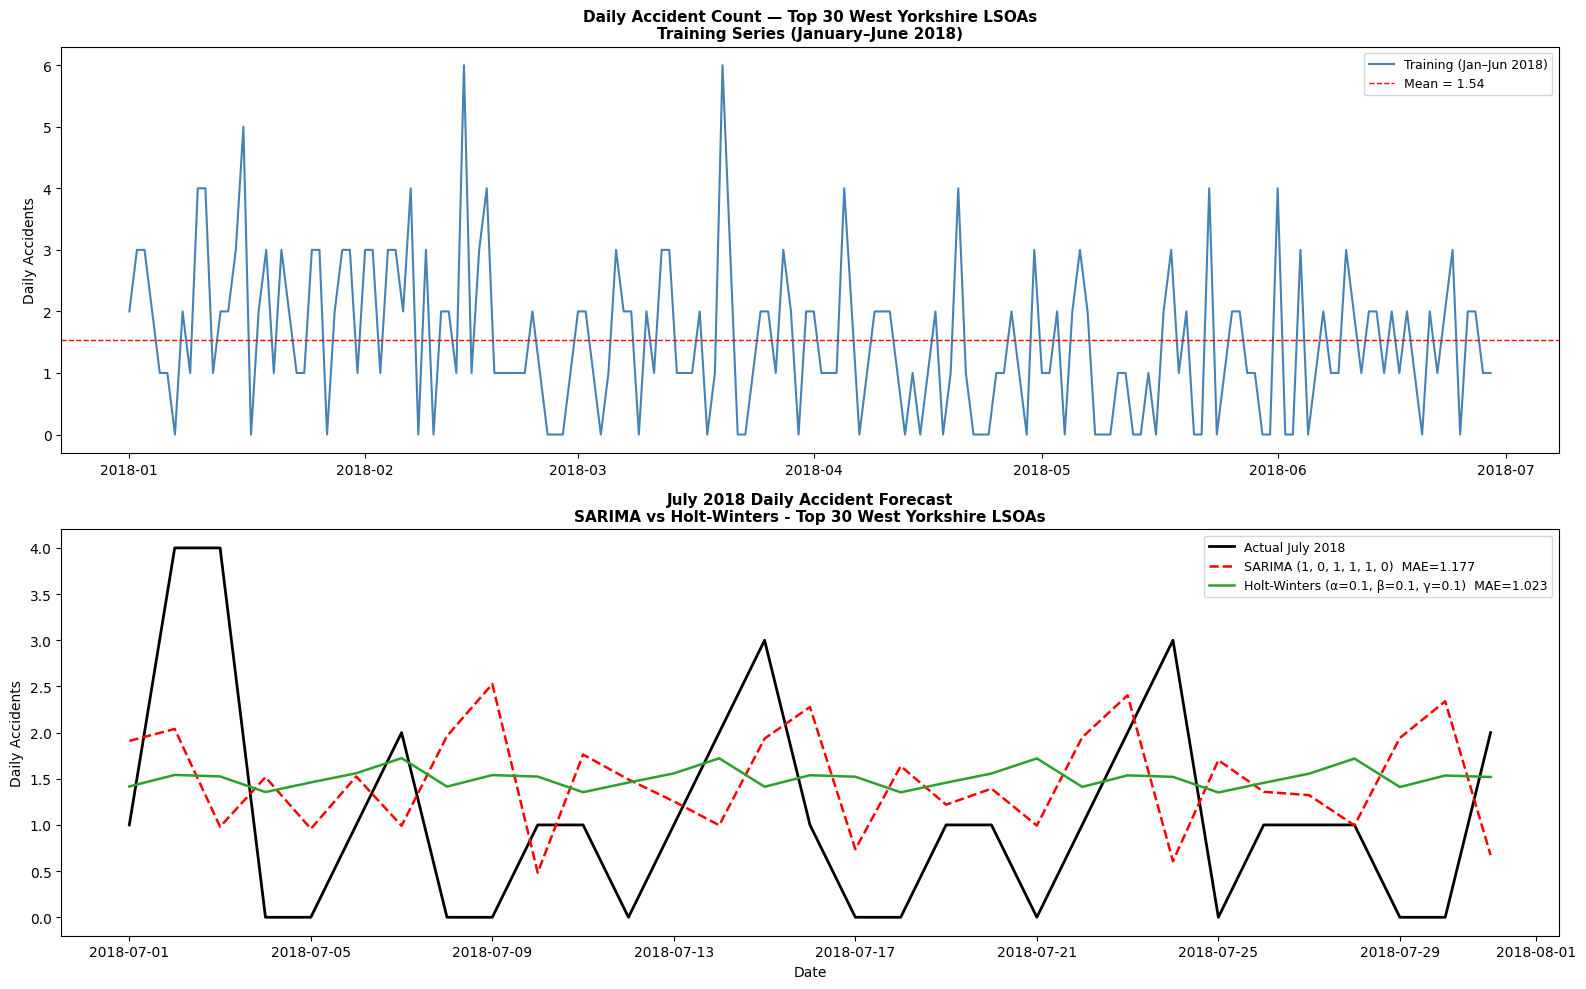

In [53]:
"""
This figure presents:
 - Training data (Jan - Jun 2018) to show historical behaviour
 - Forecast comparison for July 2018 (SARIMA vs Holt-Winters)
 - Visual and numerical evaluation of model performance
"""

# Create figure with two stacked subplots
fig, axes = plt.subplots(2, 1, figsize=(16, 10))


# Top subplot: Training data (Jan–Jun 2018)
axes[0].plot(
    daily_train.index, daily_train.values,
    color='steelblue', linewidth=1.5,
    label='Training (Jan–Jun 2018)'
)

# Add horizontal line showing mean accident level
axes[0].axhline(
    daily_train.mean(),
    color='red', linestyle='--', linewidth=1,
    label=f'Mean = {daily_train.mean():.2f}'
)

# Formatting
axes[0].set_title(
    'Daily Accident Count — Top 30 West Yorkshire LSOAs\n'
    'Training Series (January–June 2018)',
    fontsize=11, fontweight='bold'
)
axes[0].set_ylabel('Daily Accidents')
axes[0].legend(fontsize=9)


# Bottom subplot: Forecast vs Actual (July 2018)
# Compares model predictions against real observed values
axes[1].plot(actual_july.index, actual_july.values,
             color='black', linewidth=2, label='Actual July 2018')

# SARIMA forecast
axes[1].plot(sarima_fc.index, sarima_fc.values,
             color='red', linestyle='--', linewidth=1.8,
             label=f'SARIMA {best_order}  MAE={mae_s:.3f}')

# Holt-Winters forecast
axes[1].plot(hw_fc.index, hw_fc.values,
             color='#2CA02C', linestyle='-', linewidth=1.8,
             label=f'Holt-Winters (α={alpha}, β={beta}, γ={gamma})  MAE={mae_h:.3f}')

# Formatting
axes[1].set_title(
    'July 2018 Daily Accident Forecast\n'
    'SARIMA vs Holt-Winters - Top 30 West Yorkshire LSOAs',
    fontsize=11, fontweight='bold'
)
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Daily Accidents')
axes[1].legend(fontsize=9)


# Final layout
plt.tight_layout()

# Display plot
plt.show()

In [54]:
# Summary of comparison
print('Model Comparison — July 2018')

# Compare key metrics
print(f'MAE: SARIMA={mae_s:.3f} ; Holt-Winters={mae_h:.3f}')
print(f'MSE: SARIMA={mse_s:.3f} ; Holt-Winters={mse_h:.3f}')
print(f'RMSE: SARIMA={rmse_s:.3f} ; Holt-Winters={rmse_h:.3f}')
print(f'MAPE%: SARIMA={mape_s:.1f}% ; Holt-Winters={mape_h:.1f}%')


# Identify best-performing model (Model with lowest MAE is considered most accurate)
best_model = 'SARIMA' if mae_s < mae_h else 'Holt-Winters'

print(f'\nBest model: {best_model} (lowest MAE)')

Model Comparison — July 2018
MAE: SARIMA=1.177 ; Holt-Winters=1.023
MSE: SARIMA=1.961 ; Holt-Winters=1.433
RMSE: SARIMA=1.400 ; Holt-Winters=1.197
MAPE%: SARIMA=53.8% ; Holt-Winters=45.6%

Best model: Holt-Winters (lowest MAE)
